# 08 · Statistics & Probability — Complete Reference

Statistics is the language of uncertainty: it tells us how to summarise data,
how much to trust a summary, and whether an observed difference is real or
just noise. Probability is the mathematical engine underneath — every
distribution, p-value and confidence interval is ultimately a probability
statement.

This notebook is the complete DSMP reference for the statistics + probability
arc (Sessions 38–46, the two *Master Probability* sessions, and the paid
Chi-Square / ANOVA sessions). Every section pairs **definitions and formulas**
with **runnable scipy / pandas / statsmodels code**, so you can revise for
interviews *and* reproduce every number you see.

```
pip install numpy pandas matplotlib seaborn scipy statsmodels
import numpy as np, pandas as pd, scipy.stats as st
```

> **Note:** every code cell runs top-to-bottom in a fresh kernel (NumPy 2.x /
> SciPy 1.14, no internet). All randomness is seeded → outputs are
> deterministic.

## ▶ Sessions covered

| # | Session | Video |
|---|---------|-------|
| #123 | Session 38 - Descriptive Statistics Part 1 | https://www.youtube.com/watch?v=Uv3Blie7F3g |
| #125 | Session 39 - Descriptive Statistics Part 2 | https://www.youtube.com/watch?v=1ndVC500-EU |
| #126 | Session 40 - Probability Distribution Functions (PDF, PMF, CDF) | https://www.youtube.com/watch?v=C_QAURbgBqY |
| #129 | Session 41 - Normal Distribution | https://www.youtube.com/watch?v=ADqYqSdtyW8 |
| #131 | Session 42 - Non-Gaussian Probability Distributions | https://www.youtube.com/watch?v=U6QCc_3zgUk |
| #134 | Session 43 - Central Limit Theorem | https://www.youtube.com/watch?v=-WmJDYBor7c |
| #135 | Session 44 - Confidence Intervals | https://www.youtube.com/watch?v=X52HK2qkiIE |
| #137 | Session 45 - Hypothesis Testing Part 1 | https://www.youtube.com/watch?v=S94mx6OL7kM |
| #138 | Session 46 - Hypothesis Testing Part 2 \| p-values \| t-tests | https://www.youtube.com/watch?v=xHTMjxx14sU |
| #139 | Session on Chi Square Tests | https://www.youtube.com/watch?v=_8DTqznosvY |
| #140 | Session on ANOVA | https://www.youtube.com/watch?v=G9ppvMWyd54 |
| #189 | Master Probability in Data Science Part 1 | https://www.youtube.com/watch?v=DUT4WEUngt0 |
| #190 | Joint \| Marginal \| Conditional Probability and Bayes' Theorem | https://www.youtube.com/watch?v=ndHDsvqmbuI |

In [1]:
%matplotlib inline

import math
import scipy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import statsmodels.stats.multicomp as mc
import warnings

# NOTE: some BLAS builds emit benign "divide by zero/overflow/invalid in matmul"
# float-status warnings for certain matrix shapes — results are exact (checked vs
# einsum). np.seterr alone does not silence them under ipykernel, so also filter
# the warnings module.
np.seterr(divide="ignore", invalid="ignore", over="ignore")
warnings.filterwarnings("ignore", message=".*encountered in matmul")

sns.set_theme(style="whitegrid", context="notebook")
np.__version__, pd.__version__, scipy.__version__


('2.2.6', '2.3.3', '1.14.1')

---
## 1. Statistics fundamentals — population, sample, variables, sampling

▶ Session 38 - Descriptive Statistics Part 1: https://www.youtube.com/watch?v=Uv3Blie7F3g

### Population vs sample — parameter vs statistic
**Population** — the *entire* set of objects you care about. **Sample** — the
subset you actually observed. Every population quantity is a **parameter**
(fixed, usually unknown); every sample quantity is a **statistic** (computable,
used to *estimate* the parameter).

| Concept | Population | Sample |
|---|---|---|
| size | $N$ | $n$ |
| mean | $\mu = \frac{1}{N}\sum x_i$ | $\bar{x} = \frac{1}{n}\sum x_i$ |
| std deviation | $\sigma$ (divide by $N$) | $s$ (divide by $n-1$) |
| variance | $\sigma^2$ | $s^2$ |
| proportion | $p$ | $\hat{p}$ |

> **Gotcha:** interviews ask *"what is the difference between a parameter and
> a statistic?"* — **P**arameter = **P**opulation (fixed truth),
**S**tatistic = **S**ample (variable, has a sampling distribution → that's
> where the whole of inferential statistics comes from).

In [2]:
# Parameter vs statistic: a seeded hypothetical population + a seeded sample
rng = np.random.default_rng(42)
population = rng.normal(loc=170, scale=8, size=10_000)      # heights of a city (cm)
sample = rng.choice(population, size=200, replace=False)     # simple random sample

print("POPULATION parameter mu    = %.3f" % population.mean())
print("SAMPLE     statistic x_bar = %.3f" % sample.mean())
print("POPULATION parameter sigma = %.3f" % population.std(ddof=0))
print("SAMPLE     statistic s     = %.3f" % sample.std(ddof=1))
print("sampling error (x_bar - mu)= %.3f" % (sample.mean() - population.mean()))


POPULATION parameter mu    = 169.918
SAMPLE     statistic x_bar = 169.835
POPULATION parameter sigma = 8.050
SAMPLE     statistic s     = 7.698
sampling error (x_bar - mu)= -0.083


### Sampling methods
| Method | Idea | Use when | Risk |
|---|---|---|---|
| Simple random | every subset of size $n$ equally likely | population is homogeneous, list available | expensive to frame the list |
| Systematic | every $k$-th element after a random start | fast, frames/streams | hidden periodicity |
| Stratified | split into strata, sample inside each | strata differ (dept, gender) | strata must be known |
| Cluster | randomly pick whole clusters, sample all inside | geography-based, cheap | clusters are similar → low info |
| Convenience | whatever is reachable | quick pilots | high selection bias |
| Snowball | participants refer participants | hidden populations | not probabilistic at all |

**Stratified beats SRS** for the same $n$ when the strata differ from each
other — the between-group variance is removed from the error term.

In [3]:
rng = np.random.default_rng(5)
# population: 30% minority group (mean 60), 70% majority (mean 50)
minority = rng.random(20_000) < 0.3
values = np.where(minority, rng.normal(60, 10, 20_000), rng.normal(50, 10, 20_000))

# simple random sample of 300
srs = values[rng.choice(20_000, 300, replace=False)].mean()

# proportional stratified sample: 90 minority + 210 majority
minor_idx = rng.choice(np.flatnonzero(minority), 90, replace=False)
major_idx = rng.choice(np.flatnonzero(~minority), 210, replace=False)
stratified = np.concatenate([values[minor_idx], values[major_idx]]).mean()

print("true mu       = %.3f" % values.mean())
print("SRS    x_bar  = %.3f  (error %.3f)" % (srs, srs - values.mean()))
print("strat. x_bar  = %.3f  (error %.3f)" % (stratified, stratified - values.mean()))


true mu       = 53.027
SRS    x_bar  = 53.851  (error 0.824)
strat. x_bar  = 52.428  (error -0.599)


### Types of variables
**By measurement scale (Stevens):**

| Scale | Ordering? | Equal gaps? | True zero? | Examples | Allowed ops |
|---|---|---|---|---|---|
| Nominal | no | no | no | gender, city, blood group | mode, $\chi^2$ |
| Ordinal | yes | no | no | rating 1–5, satisfaction, rank | median, Spearman |
| Interval | yes | yes | no | temperature °C, calendar year | mean, Pearson $r$ |
| Ratio | yes | yes | **yes** | height, income, count | everything (log, CV) |

**By value type:** *discrete* (countable, gaps: number of children, dice)
vs *continuous* (measurable, any value in an interval: height, time).
**Categorical vs numerical** is the split that decides which summary
statistics and which test you may use.

> **Gotcha:** you may **not** compute a mean of an ordinal scale (mean of
> "satisfied = 3, neutral = 2..." is meaningless), and a coefficient of
> variation needs a **ratio** scale (true zero).

In [4]:
# categorical vs numerical summaries on a tiny survey frame
survey = pd.DataFrame({
    "gender": ["F", "M", "F", "M", "F", "M", "F"],
    "rating": [5, 2, 4, 3, 5, 1, 4],           # ordinal
    "age":    [23, 41, 35, 29, 52, 33, 27],     # ratio
})
print(survey.dtypes.to_string(), "\n")
print("nominal  -> counts:\n", survey["gender"].value_counts().to_string())
print("ordinal  -> median/mode:", survey["rating"].median(), survey["rating"].mode().iloc[0])
print("ratio    -> mean/std  : %.2f / %.2f" % (survey["age"].mean(), survey["age"].std(ddof=1)))


gender    object
rating     int64
age        int64 

nominal  -> counts:
 gender
F    4
M    3
ordinal  -> median/mode: 4.0 4
ratio    -> mean/std  : 34.29 / 9.74


**Section notes — fundamentals:**

| Term | One-liner |
|---|---|
| population / sample | all objects / observed subset |
| parameter / statistic | $\mu,\sigma,p$ / $\bar{x},s,\hat{p}$ |
| sampling error | $\bar{x}-\mu$ — the cost of not measuring everyone |
| scales | nominal → ordinal → interval → ratio (information grows) |
| sampling | SRS, systematic, stratified, cluster, convenience, snowball |

---
## 2. Central tendency — mean, median, mode and friends

▶ Session 38 - Descriptive Statistics Part 1: https://www.youtube.com/watch?v=Uv3Blie7F3g
▶ Session 39 - Descriptive Statistics Part 2: https://www.youtube.com/watch?v=1ndVC500-EU

### `statistics.mean` / `np.mean` / `Series.mean()`
**What it does:** arithmetic mean — the "balance point" of the data.
**Formula:** $\bar{x} = \dfrac{1}{n}\displaystyle\sum_{i=1}^{n} x_i$
**Returns:** a single float.
**Example:**

In [5]:
x = np.array([2, 4, 4, 4, 5, 5, 7, 9], dtype=float)
print("sum / n :", x.sum() / len(x))
print("np.mean :", np.mean(x))          # identical
print("Series  :", pd.Series(x).mean())
# even-count MEDIAN rule: average of the two middle values
ev = np.array([1.0, 3, 5, 9])
print("median of [1,3,5,9] =", np.median(ev), "= (3+5)/2 ->", (3 + 5) / 2)


sum / n : 5.0
np.mean : 5.0
Series  : 5.0
median of [1,3,5,9] = 4.0 = (3+5)/2 -> 4.0


### `Series.mode()`
**What it does:** most frequent value(s). Works on any dtype; **returns a
Series** (data can be multimodal), so index with `.iloc[0]`.
**Syntax:** `s.mode(dropna=True)`

**Returns:** a Series of tied modes in sorted order.

In [6]:
scores = pd.Series([55, 60, 60, 65, 65, 65, 70, 80, 90, 90])
print("modes       :", scores.mode().tolist())        # [65]  (unimodal)
print("first mode  :", scores.mode().iloc[0])         # 65
print("multimodal  :", pd.Series([1, 1, 2, 2, 3]).mode().tolist())   # [1, 2]
print("continuous data -> nearly all unique:",
      pd.Series(rng.normal(0, 1, 12)).round(2).mode().tolist()[:3], "...")


modes       : [65]
first mode  : 65
multimodal  : [1, 2]
continuous data -> nearly all unique: [-1.42, -1.03, -0.9] ...


### `np.average(a, weights=w)` — weighted mean
**Formula:** $\bar{x}_w = \dfrac{\sum w_i x_i}{\sum w_i}$
**Use when:** observations have different importance (survey weights, credit
hours, portfolio positions). Plain mean = weighted mean with equal weights.

In [7]:
hours = np.array([4, 3, 4, 2, 3], dtype=float)      # study hours per subject
grade = np.array([78, 85, 90, 70, 88], dtype=float) # grade in each
credits = np.array([4, 3, 4, 1, 3], dtype=float)    # credit hours (weights)
print("simple   mean grade :", np.mean(grade))
print("weighted mean grade :", np.average(grade, weights=credits))


simple   mean grade : 82.2
weighted mean grade : 84.06666666666666


### `scipy.stats.gmean(a)` — geometric mean
**Formula:** $\Big(\prod x_i\Big)^{1/n} = \exp\big(\overline{\ln x}\big)$
**Use when:** data are **multiplicative** — growth rates, ratios, index
numbers, compound returns. Requires **positive** values (for returns, average
the growth factors `1 + r` instead).

In [8]:
returns = np.array([0.10, -0.05, 0.20, 0.04, -0.08])   # +10%, -5%, ...
factors = 1 + returns                                   # strictly positive
print("arithmetic mean of returns :", round(np.mean(returns), 4))
print("geometric mean of factors  :", round(st.gmean(factors), 4),
      "-> avg growth = %.4f" % (st.gmean(factors) - 1))
print("compound growth check      : %.4f"
      % (np.prod(factors) ** (1 / 5) - 1))
# NOTE: geometric mean <= arithmetic mean, equality only when all values equal
print("gmean([100, 200, 400]) =", st.gmean([100, 200, 400]))   # 200.0


arithmetic mean of returns : 0.042
geometric mean of factors  : 1.0371 -> avg growth = 0.0371
compound growth check      : 0.0371
gmean([100, 200, 400]) = 199.99999999999991


### `scipy.stats.hmean(a)` — harmonic mean
**Formula:** $\dfrac{n}{\sum 1/x_i}$
**Use when:** averaging **rates** with a fixed denominator — speed over equal
distances, price/earnings ratios, precision of a classifier. Also positive-only.

In [9]:
speeds = np.array([60.0, 60.0, 60.0])      # km/h on each leg of equal distance
speeds2 = np.array([30.0, 90.0, 60.0])     # same distance, different speeds
print("hmean equal speeds   :", st.hmean(speeds), "km/h")
print("hmean varied speeds  :", st.hmean(speeds2), "km/h")
print("arithmetic (WRONG)   :", np.mean(speeds2), "km/h")
# reality check: 120 km at 30, 120 km at 90, 120 km at 60 -> total 360/6 h
print("true average speed   :", 360 / (120 / 30 + 120 / 90 + 120 / 60), "km/h")


hmean equal speeds   : 60.0 km/h
hmean varied speeds  : 49.090909090909086 km/h
arithmetic (WRONG)   : 60.0 km/h
true average speed   : 49.09090909090909 km/h


### `scipy.stats.trim_mean(a, proportiontocut)` — trimmed mean
**What it does:** cuts that fraction from **each tail**, then takes the mean of
the rest — a compromise between mean (uses all data) and median (uses one point).
**Parameters:** `proportiontocut` — fraction per tail, e.g. `0.1` = drop 10% from
both ends (so 0.25 each side = median).

In [10]:
rng = np.random.default_rng(7)
income = np.concatenate([rng.normal(45, 12, 500),        # bulk
                         rng.normal(120, 25, 30),        # upper tail
                         [400.0, 450.0, 500.0]])         # billionaires
print("mean        : %8.2f  (pulled up by outliers)" % income.mean())
print("median      : %8.2f" % np.median(income))
print("trim 10%%    : %8.2f" % st.trim_mean(income, 0.10))
print("trim 25%%    : %8.2f  (= median)" % st.trim_mean(income, 0.25))


mean        :    49.73  (pulled up by outliers)
median      :    44.42
trim 10%    :    44.74
trim 25%    :    44.47  (= median)


### Which measure when?

| Measure | Use when | Outlier-safe? | Notes |
|---|---|---|---|
| mean | symmetric data; basis of inference (CLT, t-tests) | **no** | uses every value |
| median | skewed data / outliers (income, prices) | **yes** | 50th percentile |
| mode | nominal/categorical, "most common" | yes | only real centre for modes |
| weighted mean | observations have unequal importance | no | survey/portfolio weights |
| geometric mean | multiplicative growth, ratios | moderate | positive data only |
| harmonic mean | equal-distance rates, speeds, P/E | high | positive data only |
| trimmed mean | want the mean but robust tails | moderate | drop 5–25% per tail |

> **Gotcha:** for right-skewed data typically **mean > median > mode**, and
> Pearson's rule of thumb gives `mode ≈ 3·median − 2·mean`. Never report only
> the mean of skewed data — always pair it with the median (or show a boxplot).

In [11]:
# all seven at once on the same skewed dataset
stats_tbl = pd.DataFrame({
    "mean":         [income.mean()],
    "median":       [np.median(income)],
    "mode(rounded)":[pd.Series(income).round(-1).mode().iloc[0]],
    "trim10":       [st.trim_mean(income, 0.10)],
    "gmean":        [st.gmean(income)],
    "hmean":        [st.hmean(income)],
    "wmean":        [np.average(income, weights=np.where(income > 100, 2.0, 1.0))],
}).T
stats_tbl.columns = ["value"]
stats_tbl.round(2)


,value
mean,49.73
median,44.42
mode(rounded),40.00
trim10,44.74
gmean,44.82
hmean,41.52
wmean,54.83


**Section notes — central tendency:**

| Function | Measure |
|---|---|
| `np.mean` / `Series.mean()` | arithmetic mean |
| `np.median` / `Series.median()` | 50th percentile |
| `Series.mode()` | most frequent (returns a Series!) |
| `np.average(x, weights=w)` | weighted mean |
| `st.gmean` / `st.hmean` | geometric / harmonic mean |
| `st.trim_mean(a, p)` | p trimmed from each tail |

---
## 3. Dispersion & shape — variance, IQR, skewness, kurtosis, z-scores

▶ Session 39 - Descriptive Statistics Part 2: https://www.youtube.com/watch?v=1ndVC500-EU

In [12]:
x = np.array([2, 4, 4, 4, 5, 5, 7, 9], dtype=float)

# range & variance (population vs sample -> the ddof gotcha)
print("range        :", np.ptp(x))                       # max - min = 7
print("var  ddof=0  : %.5f  <- population (÷ n)"   % x.var(ddof=0))
print("var  ddof=1  : %.5f  <- sample     (÷ n-1)" % x.var(ddof=1))
print("std ddof=0/1 : %.5f / %.5f" % (x.std(ddof=0), x.std(ddof=1)))
print("pandas var   : %.5f  <- ddof=1 BY DEFAULT" % pd.Series(x).var())
print("numpy  var   : %.5f  <- ddof=0 BY DEFAULT" % x.var())

# quartiles, IQR, fences
q1, q2, q3 = np.percentile(x, [25, 50, 75])
iqr = q3 - q1
print("Q1=%.2f  Q2=%.2f  Q3=%.2f  IQR=%.2f" % (q1, q2, q3, iqr))
print("fences: [%.2f, %.2f]" % (q1 - 1.5 * iqr, q3 + 1.5 * iqr))

# MAD & coefficient of variation
mad = np.median(np.abs(x - np.median(x)))
print("MAD (median abs deviation):", mad)
print("CV = 100 * s / x_bar      : %.2f%%" % (100 * x.std(ddof=1) / x.mean()))

# z-scores: standardise to "number of std deviations from the mean"
z = (x - x.mean()) / x.std(ddof=1)
print("z-scores      :", np.round(z, 3))
print("mean(z)=0, std(z)=1 :", round(z.mean(), 12), round(z.std(ddof=1), 12))


range        : 7.0
var  ddof=0  : 4.00000  <- population (÷ n)
var  ddof=1  : 4.57143  <- sample     (÷ n-1)
std ddof=0/1 : 2.00000 / 2.13809
pandas var   : 4.57143  <- ddof=1 BY DEFAULT
numpy  var   : 4.00000  <- ddof=0 BY DEFAULT
Q1=4.00  Q2=4.50  Q3=5.50  IQR=1.50
fences: [1.75, 7.75]
MAD (median abs deviation): 0.5
CV = 100 * s / x_bar      : 42.76%
z-scores      : [-1.403 -0.468 -0.468 -0.468  0.     0.     0.935  1.871]
mean(z)=0, std(z)=1 : 0.0 1.0


In [13]:
# skewness & kurtosis: scipy defaults differ from pandas!
vals = np.concatenate([x, [20.0, 30.0]])     # add a heavy right tail
print("scipy skew  bias=True  (÷ n)    : %+.4f" % st.skew(vals, bias=True))
print("scipy skew  bias=False (÷ n-1..): %+.4f" % st.skew(vals, bias=False))
print("pandas Series.skew() (unbiased) : %+.4f" % pd.Series(vals).skew())
print("scipy kurtosis fisher=True  -> EXCESS (normal = 0)  : %+.4f"
      % st.kurtosis(vals, fisher=True))
print("scipy kurtosis fisher=False -> PEARSON (normal = 3) : %+.4f"
      % st.kurtosis(vals, fisher=False))
print("pandas Series.kurt() -> excess like fisher=True     : %+.4f"
      % pd.Series(vals).kurt())


scipy skew  bias=True  (÷ n)    : +1.5873
scipy skew  bias=False (÷ n-1..): +1.8823
pandas Series.skew() (unbiased) : +1.8823
scipy kurtosis fisher=True  -> EXCESS (normal = 0)  : +1.1038
scipy kurtosis fisher=False -> PEARSON (normal = 3) : +4.1038
pandas Series.kurt() -> excess like fisher=True     : +2.9157


In [14]:
# percentiles / quantiles — three equivalent routes
data = rng.normal(100, 15, 1000)
print("np.percentile   :", np.percentile(data, [0, 25, 50, 75, 100]).round(2))
print("np.quantile     :", np.quantile(data, [0.0, 0.25, 0.5, 0.75, 1.0]).round(2))
print("pandas.quantile :", pd.Series(data).quantile([0, .25, .5, .75, 1]).round(2).to_dict())
print("interpolation='linear' (default) vs 'nearest' vs 'midpoint':")
print("  np.percentile([1,2,3], 50)                 =", np.percentile([1, 2, 3], 50))
print("  np.percentile([1,2,3,4], 50, method='nearest') =",
      np.percentile([1, 2, 3, 4], 50, method="nearest"))


np.percentile   : [ 58.3   89.84  99.45 109.98 142.43]
np.quantile     : [ 58.3   89.84  99.45 109.98 142.43]
pandas.quantile : {0.0: 58.3, 0.25: 89.84, 0.5: 99.45, 0.75: 109.98, 1.0: 142.43}
interpolation='linear' (default) vs 'nearest' vs 'midpoint':
  np.percentile([1,2,3], 50)                 = 2.0
  np.percentile([1,2,3,4], 50, method='nearest') = 3


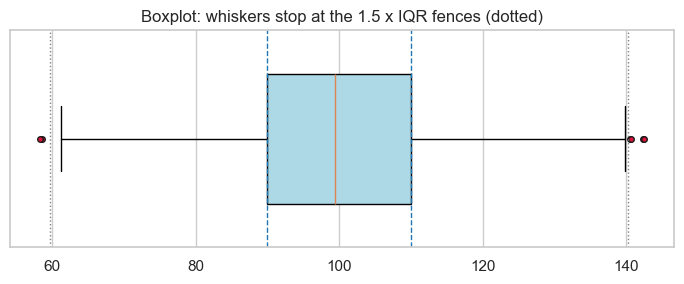

In [15]:
# boxplot fences visualised: Q1 - 1.5*IQR ... Q3 + 1.5*IQR
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot(data, vert=False, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="lightblue"),
           flierprops=dict(marker="o", ms=4, mfc="crimson", mec="k"))
ax.axvline(q1 := np.percentile(data, 25), color="tab:blue", ls="--", lw=1)
ax.axvline(q3 := np.percentile(data, 75), color="tab:blue", ls="--", lw=1)
iqr_d = q3 - q1
ax.axvline(q1 - 1.5 * iqr_d, color="gray", ls=":", lw=1)
ax.axvline(q3 + 1.5 * iqr_d, color="gray", ls=":", lw=1)
ax.set_title("Boxplot: whiskers stop at the 1.5 x IQR fences (dotted)")
ax.set_yticks([])
plt.tight_layout()
plt.show()


### The `ddof` gotcha (interview favourite)

| Library | `var` / `std` default | divides by |
|---|---|---|
| `np.var`, `np.std` | `ddof=0` | $n$ (population) |
| `pd.Series.var`, `.std` | `ddof=1` | $n-1$ (sample → Bessel correction) |
| `scipy.stats.skew(..., bias=True)` | biased | $n$ |
| `scipy.stats.kurtosis(..., bias=True)` | biased | $n$ |

$s^2 = \frac{1}{n-1}\sum (x_i-\bar{x})^2$ is **unbiased** for $\sigma^2$:
dividing by $n$ systematically underestimates because the deviations are taken
around the *sample* mean (they must sum to 0 → only $n-1$ free degrees of freedom).

> **Gotcha:** **std vs IQR vs MAD** — std uses every value (outlier-hungry,
> pairs with the mean); IQR and MAD are percentile-based (outlier-proof, pair
> with the median). Report `median (IQR)` for skewed data, `mean ± sd` for
> roughly symmetric data.

> **Gotcha:** **kurtosis convention** — SciPy default `fisher=True` returns
> *excess* kurtosis (normal → 0); `fisher=False` returns Pearson kurtosis
> (normal → 3). Pandas `.kurt()` is excess. Never compare numbers without
> checking which convention produced them.

In [16]:
# coefficient of variation — dispersion PER UNIT of the mean (scale-free)
a = np.array([10.0, 12, 14, 13, 11])
b = a * 100                       # same shape, 100x the scale
print("sd a = %.3f, CV a = %.2f%%" % (a.std(ddof=1), 100 * a.std(ddof=1) / a.mean()))
print("sd b = %.3f, CV b = %.2f%%" % (b.std(ddof=1), 100 * b.std(ddof=1) / b.mean()))
# z-score worked example: exam 85, class mean 70, sd 10
print("z of 85 =", (85 - 70) / 10, "-> percentile = %.1f%%" % (100 * st.norm.cdf(1.5)))


sd a = 1.581, CV a = 13.18%
sd b = 158.114, CV b = 13.18%
z of 85 = 1.5 -> percentile = 93.3%


**Section notes — dispersion:**

| Measure | Formula | Robust? |
|---|---|---|
| range | $\max-\min$ | no |
| variance / std | $\frac{\sum(x-\bar x)^2}{n-1}$ | no |
| IQR | $Q_3-Q_1$ | yes |
| MAD | $\text{median}\|x-\text{median}(x)\|$ | yes |
| CV | $100\cdot s/\bar{x}$ (ratio scale only) | no |
| skewness | $\mu_3/\sigma^3$ | no |
| kurtosis | $\mu_4/\sigma^4$ (excess − 3) | no |
| z-score | $(x-\bar x)/s$ | no |

---
## 4. Moments, the empirical rule, Chebyshev & the z-table

▶ Session 39 - Descriptive Statistics Part 2: https://www.youtube.com/watch?v=1ndVC500-EU
▶ Session 41 - Normal Distribution: https://www.youtube.com/watch?v=ADqYqSdtyW8

### The four moments
A **moment** is an average of powers of deviations from the centre.

| Order | Name | Formula | Measures | Estimate (`scipy.stats.moment`) |
|---|---|---|---|---|
| 1st | mean (raw) | $\mu_1=\frac1n\sum x_i$ | location | `moment(a, 1, center=0)` |
| 2nd | variance (central) | $\mu_2=\frac1n\sum(x_i-\mu)^2$ | spread | `moment(a, 2)` |
| 3rd | skewness (standardised) | $\gamma=\mu_3/\sigma^3$ | asymmetry | `moment(a,3)/moment(a,2)**1.5` |
| 4th | kurtosis (standardised) | $\kappa=\mu_4/\sigma^2$ | tail weight | `moment(a,4)/moment(a,2)**2` |

`moment(a, k, center=0)` → **raw** moment $\frac1n\sum x_i^k$;
`moment(a, k)` → **central** moment (centre defaults to the mean).

In [17]:
a = np.array([2.0, 4, 4, 4, 5, 5, 7, 9])
raw = [st.moment(a, k, center=0) for k in (1, 2, 3, 4)]
cen = [st.moment(a, k) for k in (1, 2, 3, 4)]
print("raw   moments m1..m4 :", np.round(raw, 4))
print("central moments mu1..4:", np.round(cen, 4))
sd = a.std()
# cen = [mu1, mu2, mu3, mu4]  -> indices 0..3
print("3rd standardised (skew)  : %+.4f" % (cen[2] / sd ** 3))
print("4th standardised (kurt)  : %+.4f" % (cen[3] / sd ** 4),
      " excess = %+.4f" % (cen[3] / sd ** 4 - 3))


raw   moments m1..m4 : [   5.     29.    190.25 1374.5 ]
central moments mu1..4: [ 0.    4.    5.25 44.5 ]
3rd standardised (skew)  : +0.6562
4th standardised (kurt)  : +2.7812  excess = -0.2188


### 68–95–99.7 (empirical) rule — for **normal** data only
$P(\mu \pm 1\sigma) = 68.27\%$, $P(\mu \pm 2\sigma) = 95.45\%$,
$P(\mu \pm 3\sigma) = 99.73\%$. Everything outside $\pm3\sigma$ is 0.27% —
that's why "3-sigma" events are called rare.

In [18]:
z_draw = np.random.default_rng(0).standard_normal(200_000)
for k in (1, 2, 3):
    sim = np.mean(np.abs(z_draw) <= k)
    exact = st.norm.cdf(k) - st.norm.cdf(-k)
    print("within +-%d sd : simulated %.4f   exact %.4f" % (k, sim, exact))
print("outside 3 sd  : simulated %.4f (0.27%% expected)" % np.mean(np.abs(z_draw) > 3))


within +-1 sd : simulated 0.6820   exact 0.6827
within +-2 sd : simulated 0.9545   exact 0.9545
within +-3 sd : simulated 0.9971   exact 0.9973
outside 3 sd  : simulated 0.0029 (0.27% expected)


### Chebyshev's inequality — distribution-free
$$P(|X-\mu| \ge k\sigma) \le \frac{1}{k^2}$$
Valid for **any** distribution with finite mean/variance (no normality needed)
— but only an upper bound, so it is *loose* for near-normal data.

In [19]:
skewed = np.random.default_rng(1).exponential(scale=2.0, size=200_000)
z = (skewed - skewed.mean()) / skewed.std()
print("population: exponential (very non-normal)\n")
for k in (2, 3, 4):
    sim = np.mean(np.abs(z) >= k)
    print("k=%d : actual P(|Z| >= %d) = %.4f   Chebyshev bound <= %.4f"
          % (k, k, sim, 1 / k ** 2))
# normal data: actual 4.55% at k=2, Chebyshev still says "at most 25%"
print("\nnormal k=2 actual:", round(np.mean(np.abs(z_draw) >= 2), 4),
      "vs bound 0.25")


population: exponential (very non-normal)

k=2 : actual P(|Z| >= 2) = 0.0498   Chebyshev bound <= 0.2500
k=3 : actual P(|Z| >= 3) = 0.0184   Chebyshev bound <= 0.1111
k=4 : actual P(|Z| >= 4) = 0.0066   Chebyshev bound <= 0.0625

normal k=2 actual: 0.0455 vs bound 0.25


### The z-table with SciPy — `norm.cdf` / `norm.ppf`
Standard normal table lookups become one-liners (no printed tables needed):
- `st.norm.cdf(z)` = area to the **left** of z  (the classic Φ(z) table)
- `st.norm.ppf(p)` = the z **cut-off** for cumulative probability p  (inverse table)

**Worked examples:**
- $P(Z \le 1.96) = $ `st.norm.cdf(1.96)` = 0.9750
- $P(0 \le Z \le 1.96) = 0.975 - 0.5 = 0.4750$
- $P(|Z| \ge 1.96) = 2 \cdot (1 - 0.975) = 0.05$  → the 5% two-tailed cut-off

In [20]:
print("P(Z <= 1.96)      = %.4f" % st.norm.cdf(1.96))
print("P(0 <= Z <= 1.96) = %.4f" % (st.norm.cdf(1.96) - 0.5))
print("P(|Z| >= 1.96)    = %.4f" % (2 * st.norm.sf(1.96)))
print("z* for 97.5th pct = %.4f" % st.norm.ppf(0.975))
print("z* for 95th  pct  = %.4f" % st.norm.ppf(0.95))
print("90%% CI z* = %.4f, 99%% CI z* = %.4f" % (st.norm.ppf(0.95), st.norm.ppf(0.995)))
# tail values are more accurate with sf than 1-cdf:
print("sf vs 1-cdf at z=6 : %.3e vs %.3e" % (st.norm.sf(6), 1 - st.norm.cdf(6)))


P(Z <= 1.96)      = 0.9750
P(0 <= Z <= 1.96) = 0.4750
P(|Z| >= 1.96)    = 0.0500
z* for 97.5th pct = 1.9600
z* for 95th  pct  = 1.6449
90% CI z* = 1.6449, 99% CI z* = 2.5758
sf vs 1-cdf at z=6 : 9.866e-10 vs 9.866e-10


**Section notes — moments & rules:**

| Tool | What for |
|---|---|
| `st.moment(a, k, center=0)` | raw moment |
| `st.moment(a, k)` | central moment |
| 68–95–99.7 | quick %s inside ±1/2/3σ **for normal data** |
| Chebyshev | guaranteed bound for **any** distribution |
| `st.norm.cdf(z)` | z-table (left-tail area) |
| `st.norm.ppf(p)` | inverse z-table (area → z) |
| `st.norm.sf(z)` | right-tail area, accurate in the far tail |

---
## 5. Bivariate analysis — covariance, Pearson, Spearman

▶ Session 39 - Descriptive Statistics Part 2: https://www.youtube.com/watch?v=1ndVC500-EU

### Covariance — `np.cov(x, y, ddof=1)`
**Formula:** $s_{xy} = \dfrac{\sum (x_i-\bar x)(y_i-\bar y)}{n-1}$
**What it does:** signed *direction* of a linear relationship.
**Returns:** a **2×2 matrix** `[[var(x), cov], [cov, var(y)]]` for two inputs;
a **0-d array** (scalar) for one input — `np.cov(x)[0, 0]` raises `IndexError`.
**Gotcha:** units are (units of x)×(units of y) → **not comparable across
variable pairs**, which is exactly why we normalise it into correlation.

In [21]:
rng = np.random.default_rng(3)
x = rng.normal(50, 10, 200)
y = 0.8 * x + rng.normal(0, 6, 200)

C = np.cov(x, y)                      # ddof=1 is the DEFAULT for np.cov
print(np.round(C, 3))
print("cov(x,y) = %+.3f   var(x) = %.3f   var(y) = %.3f" % (C[0, 1], C[0, 0], C[1, 1]))
print("single input -> shape:", np.cov(x).shape, "(0-d array, not (1,1))")
print("cov(x, x) == var(x):", np.isclose(np.cov(x, x)[0, 1], x.var(ddof=1)))


[[106.643  87.344]
 [ 87.344 106.606]]
cov(x,y) = +87.344   var(x) = 106.643   var(y) = 106.606
single input -> shape: () (0-d array, not (1,1))
cov(x, x) == var(x): True


### `scipy.stats.pearsonr(x, y)` — Pearson correlation coefficient
**Formula:** $r = \dfrac{s_{xy}}{s_x s_y} \in [-1, 1]$
**Assumptions:** both variables **interval/ratio**, relationship **linear**,
roughly **bivariate normal** (for the p-value), no dominant outliers.
**Parameters:** `x, y` — equal-length 1-D arrays.
**Returns:** `(r, p-value)` — the p-value tests $H_0: \rho = 0$.

In [22]:
r, p = st.pearsonr(x, y)
rho, p_rho = st.spearmanr(x, y)
print("Pearson  r = %+.3f  (p = %.2e)" % (r, p))
print("Spearman rho = %+.3f  (p = %.2e)" % (rho, p_rho))

# monotonic-but-nonlinear: Pearson under-reads, Spearman does not
t = rng.uniform(1, 10, 150)
curve = t ** 3 + rng.normal(0, 40, 150)
print("\nx vs x^3:  Pearson %.3f | Spearman %.3f"
      % (st.pearsonr(t, curve)[0], st.spearmanr(t, curve)[0]))

# outlier sensitivity: one bad point wrecks r, rho barely moves
xo = np.concatenate([x, [150.0]])
yo = np.concatenate([y, [5.0]])        # far-right x, very low y -> lever point
print("clean data   : Pearson %.3f | Spearman %.3f" % (st.pearsonr(x, y)[0],
                                                       st.spearmanr(x, y)[0]))
print("+1 outlier   : Pearson %.3f | Spearman %.3f" % (st.pearsonr(xo, yo)[0],
                                                       st.spearmanr(xo, yo)[0]))


Pearson  r = +0.819  (p = 1.08e-49)
Spearman rho = +0.800  (p = 1.04e-45)

x vs x^3:  Pearson 0.919 | Spearman 0.944
clean data   : Pearson 0.819 | Spearman 0.800
+1 outlier   : Pearson 0.525 | Spearman 0.773


### `scipy.stats.spearmanr(x, y)` — Spearman's rank correlation
**What it does:** Pearson correlation computed on the **ranks** of x and y —
$\rho = r(\text{rank}(x), \text{rank}(y))$.
**Use when:** ordinal data, monotone-but-nonlinear relations, outliers present.
**Returns:** `(rho, p-value)`.

| | Pearson $r$ | Spearman $\rho$ |
|---|---|---|
| measures | **linear** association | **monotonic** association |
| input | raw values | ranks |
| scale | interval/ratio | at least ordinal |
| outliers | very sensitive | robust |

> **Gotcha — correlation ≠ causation:** $r$ only co-moves. The classic
> ice-cream ↔ drownings correlation is driven by a **confounder** (temperature).
> Causal claims need design (randomisation) or methods (instrumental variables,
> DAGs), not a bigger $r$.

In [23]:
# spurious correlation driven by a hidden third variable
rng = np.random.default_rng(11)
months = 150
temp = rng.normal(30, 6, months)
ice_cream_sales = 0.9 * temp + rng.normal(0, 4, months)
drownings = 0.6 * temp + rng.normal(0, 5, months)

print("corr(ice cream, drownings)          = %+.3f  <- looks causal!" %
      np.corrcoef(ice_cream_sales, drownings)[0, 1])

# partial it out: regress each on temperature, correlate the residuals
res_ice = ice_cream_sales - np.polyval(np.polyfit(temp, ice_cream_sales, 1), temp)
res_drn = drownings - np.polyval(np.polyfit(temp, drownings, 1), temp)
print("corr(residuals | temperature)       = %+.3f  <- the real relationship" %
      np.corrcoef(res_ice, res_drn)[0, 1])


corr(ice cream, drownings)          = +0.558  <- looks causal!
corr(residuals | temperature)       = +0.035  <- the real relationship


### Correlation matrix + annotated heatmap

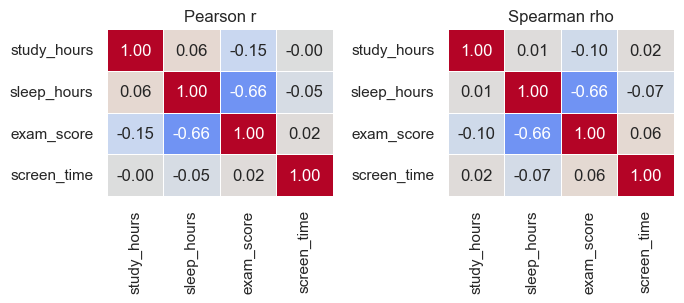

             study_hours  sleep_hours  exam_score  screen_time
study_hours        1.000        0.063      -0.146       -0.001
sleep_hours        0.063        1.000      -0.661       -0.052
exam_score        -0.146       -0.661       1.000        0.022
screen_time       -0.001       -0.052       0.022        1.000


In [24]:
rng = np.random.default_rng(21)
n = 300
s = rng.normal(0, 1, n)
df = pd.DataFrame({
    "study_hours": np.abs(s) * 2 + rng.normal(0, 0.5, n),
    "sleep_hours": 7 - s * 1.5 + rng.normal(0, 1, n),
    "exam_score": 60 + s * 3 + rng.normal(0, 2, n),
    "screen_time": rng.exponential(3, n),
})

corr_p = df.corr(method="pearson")
corr_s = df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for ax, mat, title in ((axes[0], corr_p, "Pearson r"),
                       (axes[1], corr_s, "Spearman rho")):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                linewidths=0.5, cbar=False, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()
print(corr_p.round(3))


**Section notes — bivariate:**

| Tool | Code | Says |
|---|---|---|
| covariance | `np.cov(x, y)` | direction only, has units |
| Pearson | `st.pearsonr(x, y)` | linear association (+ p-value) |
| Spearman | `st.spearmanr(x, y)` | monotonic association, rank-based |
| matrix | `df.corr()` / `df.corr(method="spearman")` | pairwise table |
| heatmap | `sns.heatmap(corr, annot=True, vmin=-1, vmax=1)` | visual check |

---
## 6. Probability basics — axioms, rules, Bayes, counting

▶ Master Probability in Data Science Part 1: https://www.youtube.com/watch?v=DUT4WEUngt0
▶ Joint | Marginal | Conditional Probability and Bayes' Theorem: https://www.youtube.com/watch?v=ndHDsvqmbuI

### Vocabulary
- **Sample space** $\Omega$ — all possible outcomes. **Event** $A \subseteq \Omega$ — a subset.
- **Axioms (Kolmogorov):** (1) $0 \le P(A) \le 1$; (2) $P(\Omega) = 1$;
  (3) for mutually exclusive events, $P(A \cup B) = P(A) + P(B)$.
- **Mutually exclusive:** $A \cap B = \emptyset$ → $P(A \cap B) = 0$.
- **Exhaustive:** $\bigcup A_i = \Omega$.

| Rule | Formula | When |
|---|---|---|
| addition | $P(A \cup B) = P(A) + P(B) - P(A \cap B)$ | always |
| addition (disjoint) | $P(A \cup B) = P(A) + P(B)$ | $A \cap B = \emptyset$ |
| multiplication | $P(A \cap B) = P(A)\,P(B \mid A) = P(B)\,P(A \mid B)$ | always |
| multiplication (independent) | $P(A \cap B) = P(A)P(B)$ | $A \perp B$ |
| complement | $P(A^c) = 1 - P(A)$ | always |
| total probability | $P(B) = \sum_i P(B \mid A_i) P(A_i)$ | $\{A_i\}$ partition $\Omega$ |

**Conditional probability:** $P(A \mid B) = \dfrac{P(A \cap B)}{P(B)}$, defined only
when $P(B) > 0$. Note $P(A \mid B) \ne P(B \mid A)$ in general — that's the
base-rate fallacy.

In [25]:
# classical vs empirical probability, and the addition/multiplication rules
S = list(range(1, 7))
A = {e for e in S if e % 2 == 0}        # even
B = {e for e in S if e > 3}             # {4,5,6}

print("P(A even) = %d/%d = %.3f" % (len(A), len(S), len(A) / len(S)))
print("P(B > 3)  = %d/%d = %.3f" % (len(B), len(S), len(B) / len(S)))
print("P(A n B)  = %d/%d = %.3f" % (len(A & B), len(S), len(A & B) / len(S)))
print("addition  : %.3f + %.3f - %.3f = %.3f  == P(A u B) = %.3f"
      % (len(A) / 6, len(B) / 6, len(A & B) / 6,
         len(A) / 6 + len(B) / 6 - len(A & B) / 6, len(A | B) / 6))

# empirical (relative frequency) — converges to classical as n grows
rng = np.random.default_rng(1)
rolls = rng.integers(1, 7, size=10_000)
print("\nclassical P(even) = 0.500   empirical = %.4f" % np.mean(rolls % 2 == 0))

# multiplication rule: independent vs dependent
P_A, P_B = 0.4, 0.5
print("\nindependent  P(A n B) = P(A)P(B)   = %.3f" % (P_A * P_B))
print("dependent    P(A n B) = P(A|B)P(B)  = %.3f  (with P(A|B) = 0.7)" % (0.7 * P_B))
print("conditional  P(A|B)   = P(A n B)/P(B)= %.3f" % (0.2 / P_B))


P(A even) = 3/6 = 0.500
P(B > 3)  = 3/6 = 0.500
P(A n B)  = 2/6 = 0.333
addition  : 0.500 + 0.500 - 0.333 = 0.667  == P(A u B) = 0.667

classical P(even) = 0.500   empirical = 0.4920

independent  P(A n B) = P(A)P(B)   = 0.200
dependent    P(A n B) = P(A|B)P(B)  = 0.350  (with P(A|B) = 0.7)
conditional  P(A|B)   = P(A n B)/P(B)= 0.400


### Bayes' theorem
$$P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)} =
\frac{P(B \mid A)\,P(A)}{\sum_i P(B \mid A_i) P(A_i)}$$
$P(A)$ = **prior** (before evidence), $P(B \mid A)$ = **likelihood**,
$P(B)$ = **evidence / normaliser**, $P(A \mid B)$ = **posterior**.

**Worked example — the medical test trap:**
a disease has prevalence 1%; the test is 99% sensitive and has a 5% false-positive
rate. You test positive — how likely are you to be sick?
$$P(D \mid +) = \frac{0.99 \times 0.01}{0.99\times0.01 + 0.05 \times 0.99} \approx 0.167$$
Only ~17% — because the healthy population is huge and produces many false positives.

In [26]:
P_D, P_pos_D, P_pos_noD = 0.01, 0.99, 0.05

# law of total probability gives the denominator P(+)
P_pos = P_pos_D * P_D + P_pos_noD * (1 - P_D)
P_D_pos = P_pos_D * P_D / P_pos                       # Bayes

print("P(D)      = %.4f  (prior)" % P_D)
print("P(+)      = %.4f  (evidence, via total probability)" % P_pos)
print("P(D|+)    = %.4f  (posterior)" % P_D_pos)
print("P(+|not D)= %.4f" % P_pos_noD)

# cross-check by simulating 200k patients
rng = np.random.default_rng(0)
N = 200_000
diseased = rng.random(N) < P_D
positive = np.where(diseased, rng.random(N) < P_pos_D, rng.random(N) < P_pos_noD)
print("simulated P(D|+) = %.4f" % (np.sum(diseased & positive) / np.sum(positive)))

# denominator really is a partition: P(+) + P(-) = 1
P_neg = (1 - P_pos_D) * P_D + (1 - P_pos_noD) * (1 - P_D)
print("P(+) + P(-) =", round(P_pos + P_neg, 12))


P(D)      = 0.0100  (prior)
P(+)      = 0.0594  (evidence, via total probability)
P(D|+)    = 0.1667  (posterior)
P(+|not D)= 0.0500
simulated P(D|+) = 0.1684
P(+) + P(-) = 1.0


### Counting — `math.comb`, `math.perm`, `math.factorial`
- **Permutations** $P(n, k) = \dfrac{n!}{(n-k)!}$ — order **matters** (`math.perm`).
- **Combinations** $C(n, k) = \dfrac{n!}{k!(n-k)!}$ — order irrelevant (`math.comb`).
- **With repetition:** $n^k$ sequences; $C(n+k-1, k)$ multisets (stars & bars).
- **Classical probability** = favourable outcomes / total outcomes (needs equiprobability).
- **Empirical probability** = relative frequency from data (works without equiprobability).

In [27]:
print("P(10,3) = math.perm(10,3) =", math.perm(10, 3))    # 720 — code sequences
print("C(10,3) = math.comb(10,3) =", math.comb(10, 3))    # 120 — committees
print("ways to arrange MISSISSIPPI:")
letters = Counter("MISSISSIPPI")
ways = math.factorial(sum(letters.values()))
for c in letters.values():
    ways //= math.factorial(c)          # 11! / (1! 4! 4! 2!)
print("   ", ways)
print("P(3 distinct dice rolls in order) =", math.perm(6, 3) / 6 ** 3)
print("P(at least 2 heads in 4 flips)    =",
      1 - st.binom.cdf(1, 4, 0.5), "=", sum(math.comb(4, k) for k in (2, 3, 4)) / 16)


P(10,3) = math.perm(10,3) = 720
C(10,3) = math.comb(10,3) = 120
ways to arrange MISSISSIPPI:
    34650
P(3 distinct dice rolls in order) = 0.5555555555555556
P(at least 2 heads in 4 flips)    = 0.6875 = 0.6875


### Frequentist vs Bayesian (one-liner each)
- **Frequentist:** probability = long-run relative frequency; $\mu$ is fixed but unknown;
  a 95% CI either covers $\mu$ or not — the *procedure* is 95% reliable.
- **Bayesian:** probability = degree of belief; $\mu$ has a *distribution* (posterior);
  after seeing data you can say $P(\mu \in CI \mid \text{data}) = 0.95$ (with a prior).

> **Gotcha:** *“probability that the parameter lies in the interval”* is a
> **Bayesian** sentence — a frequentist 95% CI does **not** mean a 95% chance
> the fixed $\mu$ is inside this particular interval (see §12).

In [28]:
# **Section notes — probability:**
#
# | Idea | Formula / code |
# |---|---|
# | addition rule | `P(A∪B) = P(A) + P(B) − P(A∩B)` |
# | multiplication | `P(A∩B) = P(A\|B)·P(B)` |
# | Bayes | `P(A\|B) = P(B\|A)·P(A) / P(B)` |
# | total probability | `P(B) = Σ P(B\|Aᵢ)P(Aᵢ)` |
# | counting | `math.perm(n,k)`, `math.comb(n,k)`, `math.factorial` |
# | empirical | frequency → `np.mean(event)` |


---
## 7. Random variables, expectations & joint distributions

▶ Session 40 - Probability Distribution Functions (PDF, PMF, CDF): https://www.youtube.com/watch?v=C_QAURbgBqY
▶ Joint | Marginal | Conditional Probability and Bayes' Theorem: https://www.youtube.com/watch?v=ndHDsvqmbuI

### Random variables
A **random variable (RV)** $X$ maps outcomes of $\Omega$ to numbers.

| | Discrete RV | Continuous RV |
|---|---|---|
| support | countable | intervals of $\mathbb R$ |
| function | **PMF** $p(x) = P(X = x)$ | **PDF** $f(x) \ge 0$, $\int f = 1$ |
| point probability | can be $> 0$ | $P(X = x) = 0$ always |
| probability of an event | $\sum_{x \in A} p(x)$ | $\int_A f(x)\,dx$ (area) |
| CDF | step function, jumps of size $p(x)$ | continuous, smooth |
| scipy | `.pmf` | `.pdf` |

**CDF (both types):** $F(x) = P(X \le x)$ — non-decreasing, right-continuous,
$F(-\infty)=0$, $F(+\infty)=1$, and $P(a < X \le b) = F(b) - F(a)$.

### Expectation and variance
$$E[X] = \sum_x x\,p(x) \quad(\text{discrete}), \qquad
E[X] = \int x f(x)\,dx \quad(\text{continuous}), \qquad
\text{Var}(X) = E[(X-\mu)^2] = E[X^2] - (E[X])^2$$
**Properties:** $E[aX+b] = aE[X]+b$ · $E[X+Y] = E[X]+E[Y]$ (no independence needed) ·
$\text{Var}(aX+b) = a^2\text{Var}(X)$ · $\text{Var}(X+Y) = \text{Var}(X)+\text{Var}(Y)+2\text{Cov}(X,Y)$.

In [29]:
# discrete RV: number of heads in 2 fair coins
vals = np.array([0, 1, 2])
pmf = np.array([0.25, 0.50, 0.25])
E = np.sum(vals * pmf)
V = np.sum((vals - E) ** 2 * pmf)
print("E[X] = %.3f   Var(X) = %.3f   sd = %.3f" % (E, V, np.sqrt(V)))
print("sanity: Var = E[X^2] - E[X]^2 = %.3f" % (np.sum(vals ** 2 * pmf) - E ** 2))

# linearity checks
a, b = 3, 5
print("E[3X+5] = %.2f (formula) / %.2f (direct)" % (a * E + b, np.sum((a * vals + b) * pmf)))
print("Var(3X+5) = %.2f (formula) / %.2f (direct)"
      % (a ** 2 * V, np.sum(((a * vals + b) - (a * E + b)) ** 2 * pmf)))

# continuous RV: X ~ Normal(mean=10, sd=2)
d = st.norm(loc=10, scale=2)
print("Normal(10, 2): E[X] = %.2f, Var = %.2f, sd = %.2f" % (d.mean(), d.var(), d.std()))


E[X] = 1.000   Var(X) = 0.500   sd = 0.707
sanity: Var = E[X^2] - E[X]^2 = 0.500
E[3X+5] = 8.00 (formula) / 8.00 (direct)
Var(3X+5) = 4.50 (formula) / 4.50 (direct)
Normal(10, 2): E[X] = 10.00, Var = 4.00, sd = 2.00


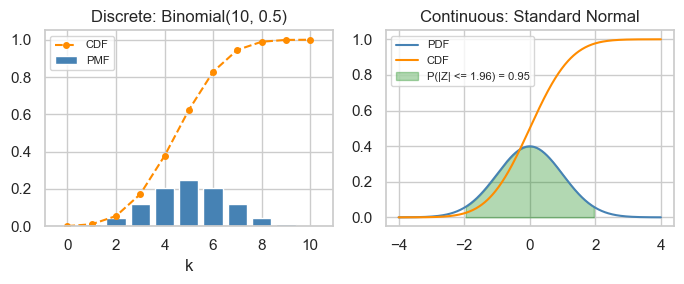

In [30]:
# plotting a PMF (steps) and a PDF/CDF
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
k = np.arange(0, 11)
axes[0].bar(k, st.binom.pmf(k, 10, 0.5), color="steelblue", label="PMF")
axes[0].plot(k, st.binom.cdf(k, 10, 0.5), "o--", ms=4, color="darkorange", label="CDF")
axes[0].set_xlabel("k"); axes[0].set_title("Discrete: Binomial(10, 0.5)")
axes[0].legend(fontsize=8)

xs = np.linspace(-4, 4, 400)
axes[1].plot(xs, st.norm.pdf(xs), color="steelblue", label="PDF")
axes[1].plot(xs, st.norm.cdf(xs), color="darkorange", label="CDF")
axes[1].fill_between(xs, 0, st.norm.pdf(xs), where=(np.abs(xs) <= 1.96),
                     alpha=0.3, color="green", label="P(|Z| <= 1.96) = 0.95")
axes[1].set_title("Continuous: Standard Normal")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


### Joint, marginal & conditional from a contingency table
For counts $n_{ij}$ with total $N$:
- **joint** $P(X=i, Y=j) = n_{ij}/N$
- **marginal** $P(X=i) = \sum_j n_{ij}/N$ (sum a row/column)
- **conditional** $P(Y=j \mid X=i) = n_{ij} / n_{i\cdot}$ (normalise a row)

In [31]:
counts = pd.DataFrame([[120, 80, 50],
                       [150, 90, 60]],
                      index=["Male", "Female"], columns=["Free", "Basic", "Pro"])
N = counts.to_numpy().sum()

joint = counts / N                       # P(gender, plan)
marg_gender = joint.sum(axis=1)          # P(gender)
marg_plan = joint.sum(axis=0)            # P(plan)
cond_plan = joint.div(marg_gender, axis=0)   # P(plan | gender)

print("N =", N)
print("\njoint P(gender, plan):\n", joint.round(4))
print("\nmarginal P(gender):\n", marg_gender.round(4))
print("\nmarginal P(plan):\n", marg_plan.round(4))
print("\nP(plan | gender)  = joint / marginal:\n", cond_plan.round(4))
print("\nsame from raw counts (n_ij / n_i.):\n",
      counts.div(counts.sum(axis=1), axis=0).round(4))
print("\nconditional rows sum to 1:", np.allclose(cond_plan.sum(axis=1), 1))


N = 550

joint P(gender, plan):
           Free   Basic     Pro
Male    0.2182  0.1455  0.0909
Female  0.2727  0.1636  0.1091

marginal P(gender):
 Male      0.4545
Female    0.5455
dtype: float64

marginal P(plan):
 Free     0.4909
Basic    0.3091
Pro      0.2000
dtype: float64

P(plan | gender)  = joint / marginal:
         Free  Basic  Pro
Male    0.48   0.32  0.2
Female  0.50   0.30  0.2

same from raw counts (n_ij / n_i.):
         Free  Basic  Pro
Male    0.48   0.32  0.2
Female  0.50   0.30  0.2

conditional rows sum to 1: True


### Independence of random variables
$X$ and $Y$ are independent iff $P(X=x, Y=y) = P(X=x)P(Y=y)$ for **all** $x, y$
(equivalently $P(Y \mid X) = P(Y)$ everywhere). If any cell differs → dependent.

In [32]:
# independent example: a fair coin and a fair die
p_coin = np.array([0.5, 0.5])                 # head/tail
p_die = np.full(6, 1 / 6)
joint_ind = np.outer(p_coin, p_die)            # P(heads AND die=k)
print("independent: max |joint - product| =",
      np.abs(joint_ind - np.outer(p_coin, p_die)).max())

# dependent example from the survey table above
p_free_male = counts.loc["Male", "Free"] / counts.loc["Male"].sum()
p_free = counts["Free"].sum() / N
print("P(Free | Male) = %.4f  vs  P(Free) = %.4f  -> dependent: %s"
      % (p_free_male, p_free, not np.isclose(p_free_male, p_free)))
# consequence: marginals do NOT determine the joint (need the conditional too)


independent: max |joint - product| = 0.0
P(Free | Male) = 0.4800  vs  P(Free) = 0.4909  -> dependent: True


**Section notes — RVs & expectations:**

| Quantity | Discrete | Continuous |
|---|---|---|
| probability law | PMF `p(x)` | PDF `f(x)` |
| CDF | `F(x) = P(X ≤ x)` (steps) | same, continuous |
| expectation | $\sum x\,p(x)$ | $\int x f(x) dx$ |
| variance | $E[X^2]-\mu^2$ | same |
| joint → marginal | sum over the other variable | integrate over it |
| independence | $p(x,y) = p(x)p(y)$ cell-by-cell | $f(x,y) = f(x)f(y)$ |

---
## 8. Distributions — the conceptual map (PMF / PDF / CDF / SF)

▶ Session 40 - Probability Distribution Functions (PDF, PMF, CDF): https://www.youtube.com/watch?v=C_QAURbgBqY

### The five functions every `scipy.stats` distribution provides

| Name | Symbol | Meaning | scipy call | Returns |
|---|---|---|---|---|
| PMF | $p(x)=P(X=x)$ | probability of an exact value | `.pmf(x)` | value in $[0,1]$ |
| PDF | $f(x)$ | density (area = probability) | `.pdf(x)` | $\ge 0$, integrates to 1 |
| CDF | $F(x)=P(X\le x)$ | left-tail area | `.cdf(x)` | value in $[0,1]$ |
| Survival | $S(x)=P(X>x)=1-F(x)$ | right-tail area | `.sf(x)` | value in $[0,1]$ |
| Inverse CDF | $F^{-1}(p)$ | quantile cut-off | `.ppf(p)` | a value of $x$ |
| Sampler | — | random draws | `.rvs(size, random_state=...)` | array |

**Moments:** `.mean()`, `.var()`, `.std()` (each distribution also has closed forms —
sections 9 & 10 list them). `.stats(moments='mvsk')` gives all four at once.

**Tail accuracy rule:** always use `.sf()` instead of `1 - .cdf()` in the far tail
(catastrophic cancellation eats the significant digits).

In [33]:
# the universal scipy.stats workflow — discrete & continuous
dist = st.norm(loc=100, scale=15)                  # continuous: Normal(100, 15)
print("pdf(100)   = %.5f" % dist.pdf(100))
print("cdf(115)   = %.5f" % dist.cdf(115))         # P(X <= 115)
print("sf(115)    = %.5f" % dist.sf(115))          # P(X >  115)
print("ppf(0.975) = %.4f" % dist.ppf(0.975))       # 97.5th percentile
print("mean/var/std = %.1f / %.1f / %.1f" % (dist.mean(), dist.var(), dist.std()))
print("rvs(random_state=42):", np.round(dist.rvs(size=4, random_state=42), 2))

b = st.binom(n=10, p=0.5)                          # discrete: Binomial(10, 0.5)
print("\npmf(3)  = %.4f   (exactly 3 heads)" % b.pmf(3))
print("cdf(3)  = %.4f   (<= 3 heads)" % b.cdf(3))
print("sf(3)   = %.4f   (>  3 heads)" % b.sf(3))
print("ppf(0.5)= %.1f" % b.ppf(0.5))               # median of the distribution
print("mean/var = %.1f / %.1f  (np / np(1-p))" % (b.mean(), b.var()))

# far tail: 1-cdf loses precision, sf does not
print("\nz = 6:  sf = %.6e   1 - cdf = %.6e" % (st.norm.sf(6), 1 - st.norm.cdf(6)))
print("cdf + sf == 1 exactly?", np.isclose(dist.cdf(100) + dist.sf(100), 1.0))


pdf(100)   = 0.02660
cdf(115)   = 0.84134
sf(115)    = 0.15866
ppf(0.975) = 129.3995
mean/var/std = 100.0 / 225.0 / 15.0
rvs(random_state=42): [107.45  97.93 109.72 122.85]

pmf(3)  = 0.1172   (exactly 3 heads)
cdf(3)  = 0.1719   (<= 3 heads)
sf(3)   = 0.8281   (>  3 heads)
ppf(0.5)= 5.0
mean/var = 5.0 / 2.5  (np / np(1-p))

z = 6:  sf = 9.865876e-10   1 - cdf = 9.865877e-10
cdf + sf == 1 exactly? True


In [34]:
# seeding: `random_state=` accepts an int OR a np.random.Generator
rng = np.random.default_rng(42)
draw_a = st.norm.rvs(size=4, random_state=42)          # int seed
draw_b = st.norm.rvs(size=4, random_state=42)          # same int -> same draw
draw_c = st.norm.rvs(size=4, random_state=rng)         # Generator -> independent stream
print("int seed reproducible :", np.allclose(draw_a, draw_b))
print("Generator works too   :", np.round(draw_c, 4))


int seed reproducible : True
Generator works too   : [ 0.3047 -1.04    0.7505  0.9406]


**Section notes — the map:**

| Question | Function |
|---|---|
| “what is P(X ≤ 75)?” | `.cdf(75)` |
| “what is P(X > 75)?” | `.sf(75)` (never `1-cdf` in the tail) |
| “where does the top 5% start?” | `.ppf(0.95)` |
| “what does a typical draw look like?” | `.rvs(..., random_state=...)` |
| “what are its mean/variance?” | `.mean()`, `.var()`, `.std()` |

> **TIP:** a distribution object is *stateless* — the same `st.norm(100, 15)`
> can be reused for pdf, cdf, ppf and sampling without “fitting” it. For an
> empirical fit use `st.norm.fit(data)` (returns MLE `loc, scale`).

---
## 9. Discrete distributions — Bernoulli … Hypergeometric

▶ Session 40 - Probability Distribution Functions (PDF, PMF, CDF): https://www.youtube.com/watch?v=C_QAURbgBqY
▶ Session 42 - Non-Gaussian Probability Distributions: https://www.youtube.com/watch?v=U6QCc_3zgUk

### `scipy.stats.bernoulli(p)`
**What it does:** one binary trial (success/failure, yes/no, click/no-click).
**Formula:** $P(X=1)=p$, $P(X=0)=1-p$.
**Parameters:** `p` — float in [0, 1] — probability of "success".
**Moments:** $E[X]=p$, $\text{Var}(X)=p(1-p)$.
**Example:** a banner ad converts with $p=0.12$ → a randomly chosen visitor
buys with probability 0.12.

PMF: {np.int64(0): np.float64(0.88), np.int64(1): np.float64(0.12)}
mean = 0.120   var = 0.10560   (p and p(1-p))
3 independent visitors, all fail: 0.6815


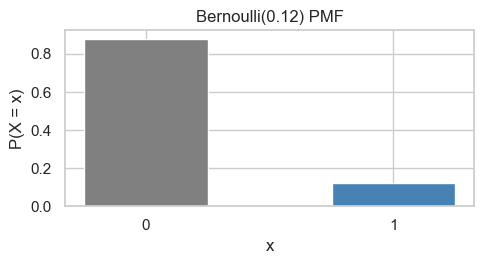

In [35]:
p_click = 0.12
xs = np.array([0, 1])
print("PMF:", dict(zip(xs, np.round(st.bernoulli.pmf(xs, p_click), 4))))
print("mean = %.3f   var = %.5f   (p and p(1-p))"
      % (st.bernoulli.mean(p_click), st.bernoulli.var(p_click)))
print("3 independent visitors, all fail: %.4f" % st.bernoulli.pmf(0, p_click) ** 3)

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(xs, st.bernoulli.pmf(xs, p_click), color=["gray", "steelblue"], width=0.5)
ax.set_xticks([0, 1]); ax.set_xlabel("x"); ax.set_ylabel("P(X = x)")
ax.set_title("Bernoulli(0.12) PMF")
plt.tight_layout(); plt.show()


### `scipy.stats.binom(n, p)`
**What it does:** number of successes in **n independent** Bernoulli trials.
**Formula:** $P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$, $\;k=0,\dots,n$.
**Parameters:** `n` — int — trials; `p` — float — success probability.
**Moments:** $E[X]=np$, $\text{Var}(X)=np(1-p)$.
**Example:** 10 fair coin flips, count heads ($n=10, p=0.5$).

k : [ 0  1  2  3  4  5  6  7  8  9 10]
P : [0.001  0.0098 0.0439 0.1172 0.2051 0.2461 0.2051 0.1172 0.0439 0.0098
 0.001 ]
P(X = 5) exactly 5 heads = 0.2461
P(X >= 8)                = 0.0547
mean = np = 5.00   var = np(1-p) = 2.50
pmf sums to 1: 1.000000000000
P(X <= 2 of 20 spam) = 0.0355


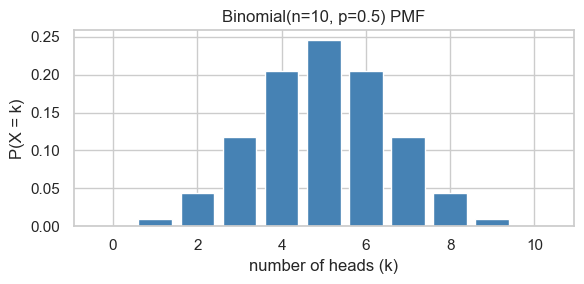

In [36]:
n_flips, p_head = 10, 0.5
k = np.arange(0, n_flips + 1)
pmf = st.binom.pmf(k, n_flips, p_head)
print("k :", k)
print("P :", np.round(pmf, 4))
print("P(X = 5) exactly 5 heads = %.4f" % st.binom.pmf(5, n_flips, p_head))
print("P(X >= 8)                = %.4f" % st.binom.sf(7, n_flips, p_head))
print("mean = np = %.2f   var = np(1-p) = %.2f"
      % (st.binom.mean(n_flips, p_head), st.binom.var(n_flips, p_head)))
print("pmf sums to 1: %.12f" % pmf.sum())

# real example: 20 emails, each spam with p = 0.30 -> P(at most 2 spam)
print("P(X <= 2 of 20 spam) = %.4f" % st.binom.cdf(2, 20, 0.30))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(k, pmf, color="steelblue")
ax.set_xlabel("number of heads (k)"); ax.set_ylabel("P(X = k)")
ax.set_title("Binomial(n=10, p=0.5) PMF")
plt.tight_layout(); plt.show()


### `scipy.stats.poisson(mu)`   (`mu` is the rate $\lambda$)
**What it does:** count of events in a fixed interval when events are **rare**,
independent, at a constant average rate $\lambda$.
**Formula:** $P(X=k)=\dfrac{e^{-\lambda}\lambda^k}{k!}$, $\;k=0,1,2,\dots$
**Parameters:** `mu` — float — expected count $\lambda$ (mean = variance = $\lambda$).
**When to use:** calls/hour, typos/page, arrivals/minute, defects/batch (any
“count of rare events”). For $\lambda<1$ the mass collapses onto 0 and 1 and the
Poisson starts to *approximate a Bernoulli trial* ($P(0)\approx1-\lambda$,
$P(1)\approx\lambda$, $P(\ge2)\approx0$).

lambda = 3.0
P(X=k): [0.0498 0.1494 0.224  0.224  0.168  0.1008 0.0504 0.0216 0.0081 0.0027
 0.0008]
P(X = 0) = 0.0498   P(X <= 2) = 0.4232   P(X > 6) = 0.0335
mean = var = lambda: 3.0 3.0

lambda = 0.2 : [0.8187 0.1637 0.0164]  (P(X>=2) ~ 0)

P(<= 2 calls | 4.5/hr) = 0.1736


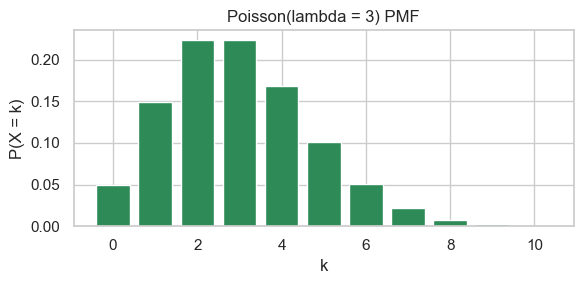

In [37]:
lam = 3.0
kk = np.arange(0, 11)
print("lambda =", lam)
print("P(X=k):", np.round(st.poisson.pmf(kk, lam), 4))
print("P(X = 0) = %.4f   P(X <= 2) = %.4f   P(X > 6) = %.4f"
      % (st.poisson.pmf(0, lam), st.poisson.cdf(2, lam), st.poisson.sf(6, lam)))
print("mean = var = lambda:", st.poisson.mean(lam), st.poisson.var(lam))

# lambda < 1 -> looks Bernoulli-like
print("\nlambda = 0.2 :", np.round(st.poisson.pmf([0, 1, 2], 0.2), 4),
      " (P(X>=2) ~ 0)")

# real example: call centre receives 4.5 calls/hour
print("\nP(<= 2 calls | 4.5/hr) = %.4f" % st.poisson.cdf(2, 4.5))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(kk, st.poisson.pmf(kk, lam), color="seagreen")
ax.set_xlabel("k"); ax.set_ylabel("P(X = k)")
ax.set_title("Poisson(lambda = 3) PMF")
plt.tight_layout(); plt.show()


### `scipy.stats.geom(p)`
**What it does:** number of **trials until the first success** (includes the success).
**Formula:** $P(X=k)=(1-p)^{k-1}p$, $\;k=1,2,\dots$  ·  $E[X]=1/p$,
$\text{Var}(X)=(1-p)/p^2$.
**Parameters:** `p` — float — success probability.
**Example:** a machine produces 5% defects → expected items until the first
defect = $1/0.05 = 20$.
> **Gotcha:** some books define geometric as *failures before* the first success
> (support 0, 1, 2 …). **SciPy uses the number of trials** (support starts at 1).

P(X = k): [0.05   0.0475 0.0451 0.0429 0.0407 0.0387 0.0368 0.0349 0.0332 0.0315
 0.0299 0.0284]
mean = 1/p = 20.0   var = (1-p)/p^2 = 380.0
P(first defect within 10 items) = P(X <= 10) = 0.4013
P(survive first 20 items) = P(X > 20) = 0.3585 = 0.95^20


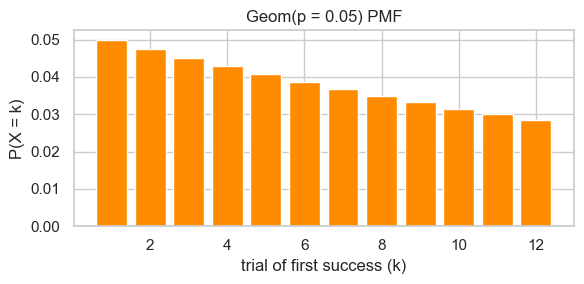

In [38]:
p_defect = 0.05
kg = np.arange(1, 13)
print("P(X = k):", np.round(st.geom.pmf(kg, p_defect), 4))
print("mean = 1/p = %.1f   var = (1-p)/p^2 = %.1f"
      % (st.geom.mean(p_defect), st.geom.var(p_defect)))
print("P(first defect within 10 items) = P(X <= 10) = %.4f"
      % st.geom.cdf(10, p_defect))
print("P(survive first 20 items) = P(X > 20) = %.4f = 0.95^20"
      % st.geom.sf(20, p_defect))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(kg, st.geom.pmf(kg, p_defect), color="darkorange")
ax.set_xlabel("trial of first success (k)"); ax.set_ylabel("P(X = k)")
ax.set_title("Geom(p = 0.05) PMF")
plt.tight_layout(); plt.show()


### `scipy.stats.nbinom(n, p)` — negative binomial (brief)
**What it does:** number of **failures before the r-th success** (SciPy's `n` = r).
**Formula:** $P(Y=k)=\binom{k+r-1}{k}p^r(1-p)^k$, $\;k=0,1,2,\dots$
· $E[Y]=\dfrac{r(1-p)}{p}$, $\text{Var}(Y)=\dfrac{r(1-p)}{p^2}$.
**Use when:** over-dispersed counts (variance > mean) — a Poisson whose rate
itself varies (insurance claims per policy, tweets per user).

mean = 4.50  var = 11.25  (var > mean -> over-dispersed)
P(Y = 3 failures) = 0.1382
P(Y <= 5) = 0.6846


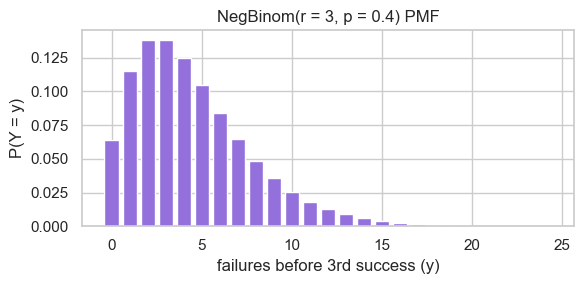

In [39]:
r, p_s = 3, 0.4
kn = np.arange(0, 25)
print("mean = %.2f  var = %.2f  (var > mean -> over-dispersed)"
      % (st.nbinom.mean(r, p_s), st.nbinom.var(r, p_s)))
print("P(Y = 3 failures) = %.4f" % st.nbinom.pmf(3, r, p_s))
print("P(Y <= 5) = %.4f" % st.nbinom.cdf(5, r, p_s))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(kn, st.nbinom.pmf(kn, r, p_s), color="mediumpurple")
ax.set_xlabel("failures before 3rd success (y)"); ax.set_ylabel("P(Y = y)")
ax.set_title("NegBinom(r = 3, p = 0.4) PMF")
plt.tight_layout(); plt.show()


### `scipy.stats.hypergeom(M, n, N)` — hypergeometric (brief)
**What it does:** successes in a draw **without replacement** (population is finite).
**Formula:** $P(X=k)=\dfrac{\binom{K}{k}\binom{M-K}{N-k}}{\binom{M}{N}}$ —
where math uses $M$ = population, $K$ = success states, $N$ = draws; SciPy's
keywords are `M`, `n` (= K) and `N` (= draws).
**Moments:** $E[X]=N\cdot K/M$.
**Use when:** quality-control sampling, lotteries, card hands, A/B tests on a
small fixed user base. With a huge population it ≈ Binomial.

P(exactly 2 defective) = 0.3874
P(at most 2 defective) = 0.7932
mean = N*K/M = 1.750
binomial approx (n=5, p=7/20): 0.3364
PMF: [0.083  0.3228 0.3874 0.1761 0.0293 0.0014]


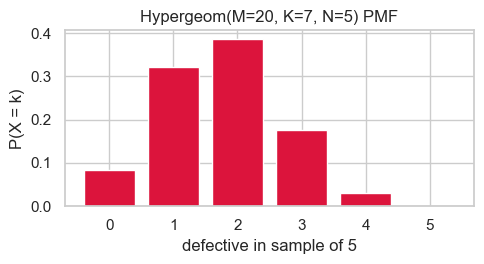

In [40]:
M, K, N = 20, 7, 5       # 20 bulbs, 7 defective, draw 5
print("P(exactly 2 defective) = %.4f" % st.hypergeom.pmf(2, M, K, N))
print("P(at most 2 defective) = %.4f" % st.hypergeom.cdf(2, M, K, N))
print("mean = N*K/M = %.3f" % st.hypergeom.mean(M, K, N))
print("binomial approx (n=5, p=7/20): %.4f"
      % st.binom.pmf(2, 5, K / M))
kh = np.arange(0, N + 1)
print("PMF:", np.round(st.hypergeom.pmf(kh, M, K, N), 4))

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(kh, st.hypergeom.pmf(kh, M, K, N), color="crimson")
ax.set_xlabel("defective in sample of 5"); ax.set_ylabel("P(X = k)")
ax.set_title("Hypergeom(M=20, K=7, N=5) PMF")
plt.tight_layout(); plt.show()


**Section notes — discrete distributions:**

| Distribution | scipy | Support | Mean | Var | Use when |
|---|---|---|---|---|---|
| Bernoulli | `st.bernoulli(p)` | {0,1} | $p$ | $p(1-p)$ | one binary trial |
| Binomial | `st.binom(n, p)` | 0..n | $np$ | $np(1-p)$ | n independent trials |
| Poisson | `st.poisson(mu)` | 0,1,2… | $\lambda$ | $\lambda$ | rare-event counts |
| Geometric | `st.geom(p)` | 1,2,3… | $1/p$ | $(1-p)/p^2$ | time to first success |
| Neg. binomial | `st.nbinom(r, p)` | 0,1,2… | $r(1-p)/p$ | $r(1-p)/p^2$ | over-dispersed counts |
| Hypergeometric | `st.hypergeom(M, K, N)` | 0..N | $NK/M$ | — | sampling w/o replacement |

---
## 10. Continuous distributions — Uniform … F

▶ Session 41 - Normal Distribution: https://www.youtube.com/watch?v=ADqYqSdtyW8
▶ Session 42 - Non-Gaussian Probability Distributions: https://www.youtube.com/watch?v=U6QCc_3zgUk

In [41]:
# helper used by every plot below: evaluate a pdf on a linspace grid
def pdf_grid(dist, lo, hi, num=400):
    xs = np.linspace(lo, hi, num)
    return xs, dist.pdf(xs)


### `scipy.stats.uniform(loc, scale)` — Uniform / continuous
**Formula:** $f(x)=\dfrac{1}{b-a}$ for $x\in[a,b]$, 0 otherwise.
**Parameters:** `loc` = a (lower bound), `scale` = b − a (width!) — not the upper bound.
**Moments:** $E[X]=a+\frac{b-a}{2}$, $\text{Var}=\frac{(b-a)^2}{12}$.
**Example:** a packet arrives uniformly between 0 and 10 minutes.

In [42]:
u = st.uniform(loc=0, scale=10)          # Uniform[0, 10]
print("mean = %.2f (a + width/2)   var = %.3f (width^2/12)"
      % (u.mean(), u.var()))
print("P(3 < X < 7) = %.3f (should be 0.4)" % (u.cdf(7) - u.cdf(3)))
print("P(X <= 10) = %.1f, P(X = 5) = %.4f (continuous -> point prob 0? density)"
      % (u.cdf(10), u.pdf(5)))


mean = 5.00 (a + width/2)   var = 8.333 (width^2/12)
P(3 < X < 7) = 0.400 (should be 0.4)
P(X <= 10) = 1.0, P(X = 5) = 0.1000 (continuous -> point prob 0? density)


### `scipy.stats.norm(loc, scale)` — Normal (Gaussian)
**Formula:** $f(x)=\dfrac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$.
**Parameters:** `loc` = μ, `scale` = σ (sd, **not variance**).
**Moments:** $E=\mu$, $\text{Var}=\sigma^2$; 68–95–99.7 inside ±1/2/3σ.
**Standard normal:** $Z=\dfrac{X-\mu}{\sigma}\sim N(0,1)$ (the z-transform).

**Worked example:** adult heights $X \sim N(165, 8^2)$ cm.
- $P(X > 170) = P(Z > 0.625) = $ `st.norm.sf(0.625)` = 0.2660
- 90th percentile: $\mu + 1.2816\sigma = 165 + 1.2816(8) \approx 175.3$ cm

In [43]:
mu_h, sd_h = 165.0, 8.0
z = (170 - mu_h) / sd_h                          # 0.625
print("z of 170 cm        = %.4f" % z)
print("P(X > 170)         = %.4f" % st.norm.sf(z))
print("P(160 < X < 170)   = %.4f"
      % (st.norm.cdf((170 - mu_h) / sd_h) - st.norm.cdf((160 - mu_h) / sd_h)))
print("90th percentile    = %.3f cm" % st.norm.ppf(0.90, loc=mu_h, scale=sd_h))
print("standard normal check: P(Z > 0.625) = %.4f" % st.norm.sf(0.625))


z of 170 cm        = 0.6250
P(X > 170)         = 0.2660
P(160 < X < 170)   = 0.4680
90th percentile    = 175.252 cm
standard normal check: P(Z > 0.625) = 0.2660


### `scipy.stats.lognorm(s, scale=exp(mu))` — Log-normal
**Formula:** if $Y\sim N(\mu,\sigma^2)$ then $X=e^{Y}$ is log-normal;
$f(x)=\dfrac{1}{x\sigma\sqrt{2\pi}}e^{-\frac{(\ln x-\mu)^2}{2\sigma^2}}$, $x>0$.
**Parameters:** SciPy uses `s` = σ (of the underlying normal) and
`scale` = $e^{\mu}$ (median of X).
**Moments:** $E[X]=e^{\mu+\sigma^2/2}$, $\text{Var}= (e^{\sigma^2}-1)e^{2\mu+\sigma^2}$.
**Use when:** multiplicative data — income, rainfall, incubation times, file sizes,
any “many small factors multiplied together” (CLT on logs).

In [44]:
mu_l, sig_l = 2.0, 0.4
ln = st.lognorm(s=sig_l, scale=np.exp(mu_l))
print("median = exp(mu)      = %.4f" % ln.median())
print("mean   = exp(mu+s^2/2)= %.4f  (formula %.4f)"
      % (ln.mean(), np.exp(mu_l + sig_l ** 2 / 2)))
print("P(X <= 10) = %.4f" % ln.cdf(10))


median = exp(mu)      = 7.3891
mean   = exp(mu+s^2/2)= 8.0045  (formula 8.0045)
P(X <= 10) = 0.7753


### `scipy.stats.expon(scale=1/lambda)` — Exponential
**Formula:** $f(x)=\lambda e^{-\lambda x}$, $x \ge 0$;
$E[X]=1/\lambda$, $\text{Var}=1/\lambda^2$ (**SciPy `scale` = β = 1/λ**).
**Memoryless property:** $P(X > s+t \mid X > s) = P(X > t)$ — a component that
survived 100 h has the *same* remaining-life distribution as a new one.
**Use when:** waiting times between Poisson events — time between failures,
time until next customer arrives.

In [45]:
mean_life = 20.0                       # hours between failures (β)
e = st.expon(scale=mean_life)
print("lambda = 1/mean = %.4f" % (1 / mean_life))
print("mean = %.1f h, sd = %.1f h" % (e.mean(), e.std()))
print("P(fail within 10 h) = 1 - e^{-0.5} = %.4f" % e.cdf(10))
print("memoryless: P(T > 30 | T > 20) = P(T > 10) = %.4f / %.4f = %.4f"
      % (e.sf(10), e.sf(0), e.sf(30) / e.sf(20)))


lambda = 1/mean = 0.0500
mean = 20.0 h, sd = 20.0 h
P(fail within 10 h) = 1 - e^{-0.5} = 0.3935
memoryless: P(T > 30 | T > 20) = P(T > 10) = 0.6065 / 1.0000 = 0.6065


### `scipy.stats.gamma(a, scale)` — Gamma (brief)
**Formula:** $f(x)=\dfrac{x^{a-1}e^{-x/\theta}}{\Gamma(a)\,\theta^{a}}$;
$E[X]=a\theta$, $\text{Var}=a\theta^2$. **`a` = shape, `scale` = θ.**
**Use when:** total time of $a$ consecutive exponential waits (sum of exponentials),
rainfall accumulation, insurance claim sizes. Exponential = Gamma with `a=1`.

In [46]:
g = st.gamma(a=3, scale=5)             # sum of 3 Exp(mean 5) waits
print("mean = a*scale = %.1f   var = a*scale^2 = %.1f" % (g.mean(), g.var()))
print("P(X <= 20) = %.4f" % g.cdf(20))
print("exponential is gamma(a=1): pdf match =",
      np.isclose(g.pdf(1), st.gamma.pdf(1, a=3, scale=5)))


mean = a*scale = 15.0   var = a*scale^2 = 75.0
P(X <= 20) = 0.7619
exponential is gamma(a=1): pdf match = True


### `scipy.stats.beta(a, b)` — Beta
**Formula:** $f(x)=\dfrac{x^{a-1}(1-x)^{b-1}}{B(a,b)}$, $x\in[0,1]$;
$E=\dfrac{a}{a+b}$, $\text{Var}=\dfrac{ab}{(a+b)^2(a+b+1)}$.
**Use when:** probabilities/proportions live in [0,1] — and as the **Bayesian
conjugate prior** for a Bernoulli/Binomial success rate: prior Beta(a, b) +
k successes in n trials → posterior Beta(a+k, b+n−k).
**Special cases:** a=b=1 → Uniform; a=b>1 → symmetric unimodal.

In [47]:
beta = st.beta(a=2, b=5)               # "2 successes-ish, 5 failures-ish"
print("mean = a/(a+b) = %.4f   mode = (a-1)/(a+b-2) = %.4f"
      % (beta.mean(), (2 - 1) / (2 + 5 - 2)))
print("P(p <= 0.5) = %.4f" % beta.cdf(0.5))
# update: prior Beta(2,5) + 8 more successes in 10 trials -> Beta(10,7)
post = st.beta(a=2 + 8, b=5 + 2)
print("posterior mean after 8/10 more: %.4f" % post.mean())


mean = a/(a+b) = 0.2857   mode = (a-1)/(a+b-2) = 0.2000
P(p <= 0.5) = 0.8906
posterior mean after 8/10 more: 0.5882


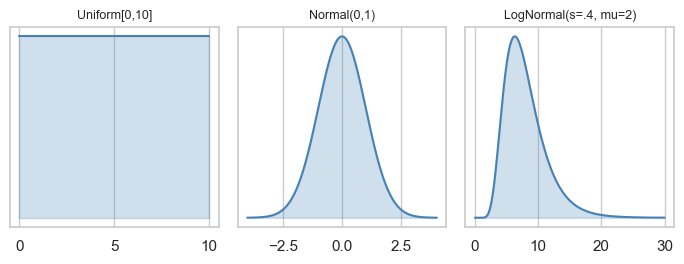

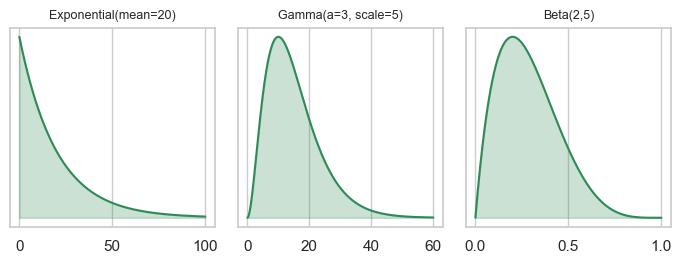

In [48]:
# pdfs: uniform / normal / log-normal
fig, axes = plt.subplots(1, 3, figsize=(7, 2.8))
for ax, (dist, lo, hi, title) in zip(axes, [
        (st.uniform(0, 10), 0, 10, "Uniform[0,10]"),
        (st.norm(0, 1), -4, 4, "Normal(0,1)"),
        (st.lognorm(s=0.4, scale=np.exp(2)), 0, 30, "LogNormal(s=.4, mu=2)")]):
    xs, ys = pdf_grid(dist, lo, hi)
    ax.plot(xs, ys, color="steelblue")
    ax.fill_between(xs, 0, ys, alpha=0.25, color="steelblue")
    ax.set_title(title, fontsize=9)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# pdfs: exponential / gamma / beta
fig, axes = plt.subplots(1, 3, figsize=(7, 2.8))
for ax, (dist, lo, hi, title) in zip(axes, [
        (st.expon(scale=20), 0, 100, "Exponential(mean=20)"),
        (st.gamma(a=3, scale=5), 0, 60, "Gamma(a=3, scale=5)"),
        (st.beta(2, 5), 0, 1, "Beta(2,5)")]):
    xs, ys = pdf_grid(dist, lo, hi)
    ax.plot(xs, ys, color="seagreen")
    ax.fill_between(xs, 0, ys, alpha=0.25, color="seagreen")
    ax.set_title(title, fontsize=9)
    ax.set_yticks([])
plt.tight_layout()
plt.show()


### `scipy.stats.chi2(df)` — Chi-square
**Formula:** sum of $df$ squared independent standard normals:
$Q = Z_1^2+\dots+Z_{df}^2$; $E=df$, $\text{Var}=2df$.
**Use when:** goodness-of-fit and independence tests (§15), sample variance
$\frac{(n-1)s^2}{\sigma^2}\sim\chi^2_{n-1}$, variances never go negative.

In [49]:
c = st.chi2(df=4)
print("mean = df = 4, var = 2df = 8   -> %.1f / %.1f" % (c.mean(), c.var()))
print("P(Q <= 9.49) at df=4 = %.4f  (the 5%% chi-square critical value)" % c.cdf(9.49))
print("chi2 with df=1 is Z^2: P(chi2 <= 3.84) = %.4f = 1 - 0.05" % st.chi2(1).cdf(3.8416))


mean = df = 4, var = 2df = 8   -> 4.0 / 8.0
P(Q <= 9.49) at df=4 = 0.9500  (the 5% chi-square critical value)
chi2 with df=1 is Z^2: P(chi2 <= 3.84) = 0.9500 = 1 - 0.05


### `scipy.stats.t(df)` — Student's t
**Why it exists:** $\sigma$ is **unknown** and $n$ is **small** — we estimate σ
with s, which adds uncertainty, fattening the tails.
**Formula:** $T = \dfrac{Z}{\sqrt{V/df}}$ with $V\sim\chi^2_{df}$, $df=n-1$.
**Key fact:** as $df \to \infty$ the t converges to the standard normal
(print the comparison below). For $df \ge 30$ they are already close.

In [50]:
print(" df  |  t.975  |  z.975 = 1.9600 | t.995")
for df in (1, 5, 10, 30, 100, 1000):
    print("%4d | %7.4f |                 | %7.4f"
          % (df, st.t.ppf(0.975, df), st.t.ppf(0.995, df)))
print("t(df=1e6) .975 = %.4f  (essentially normal)" % st.t.ppf(0.975, 1_000_000))


 df  |  t.975  |  z.975 = 1.9600 | t.995
   1 | 12.7062 |                 | 63.6567
   5 |  2.5706 |                 |  4.0321
  10 |  2.2281 |                 |  3.1693
  30 |  2.0423 |                 |  2.7500
 100 |  1.9840 |                 |  2.6259
1000 |  1.9623 |                 |  2.5808
t(df=1e6) .975 = 1.9600  (essentially normal)


### `scipy.stats.f(dfn, dfd)` — F distribution
**Formula:** $F = \dfrac{U/dfn}{V/dfd}$, $U\sim\chi^2_{dfn}$, $V\sim\chi^2_{dfd}$ (independent).
**Use when:** comparing variances and — the big one — **ANOVA** (§16), where
$F = \text{MSB}/\text{MSW}$ with $dfn=k-1$, $dfd=n-k$.
**Note:** $F_{dfn,1} = t_{dfn}^2$ — the t-test is a special case of the F-test.

In [51]:
f = st.f(dfn=2, dfd=15)
print("E[F] = dfd/(dfd-2) = %.4f (for dfd > 2)" % f.mean())
print("P(F <= 3.68) at df(2,15) = %.4f  (5%% critical value ~0.95)" % f.cdf(3.68))
print("F(2, 15) critical 5%% = %.3f" % f.ppf(0.95))


E[F] = dfd/(dfd-2) = 1.1538 (for dfd > 2)
P(F <= 3.68) at df(2,15) = 0.9499  (5% critical value ~0.95)
F(2, 15) critical 5% = 3.682


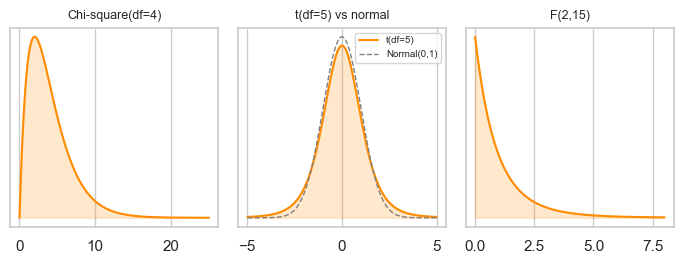

In [52]:
# pdfs: chi-square / t / F
fig, axes = plt.subplots(1, 3, figsize=(7, 2.8))
for ax, (dist, lo, hi, title) in zip(axes, [
        (st.chi2(4), 0, 25, "Chi-square(df=4)"),
        (st.t(5), -5, 5, "t(df=5) vs normal"),
        (st.f(2, 15), 0, 8, "F(2,15)")]):
    xs, ys = pdf_grid(dist, lo, hi)
    ax.plot(xs, ys, color="darkorange", label=title.split(" vs")[0])
    if "vs normal" in title:
        ax.plot(xs, st.norm.pdf(xs), ls="--", color="gray", lw=1, label="Normal(0,1)")
        ax.legend(fontsize=7)
    ax.fill_between(xs, 0, ys, alpha=0.2, color="darkorange")
    ax.set_title(title, fontsize=9)
    ax.set_yticks([])
plt.tight_layout()
plt.show()


**Section notes — continuous distributions:**

| Distribution | scipy | Support | Key params | Use when |
|---|---|---|---|---|
| Uniform | `st.uniform(a, b-a)` | [a, b] | loc, scale=width | equal likelihood everywhere |
| Normal | `st.norm(mu, sigma)` | (−∞, ∞) | loc, scale | errors, sums, natural variation |
| Log-normal | `st.lognorm(s, scale=e^mu)` | (0, ∞) | s=σ, scale=e^μ | multiplicative data |
| Exponential | `st.expon(scale=1/λ)` | [0, ∞) | scale=1/λ | memoryless waiting times |
| Gamma | `st.gamma(a, scale)` | [0, ∞) | shape, scale | sums of waits, accumulation |
| Beta | `st.beta(a, b)` | [0, 1] | α, β | proportions, Bayesian prior |
| Chi-square | `st.chi2(df)` | [0, ∞) | df | GOF, variances, independence |
| t | `st.t(df)` | (−∞, ∞) | df = n−1 | unknown σ, small n |
| F | `st.f(dfn, dfd)` | [0, ∞) | two dfs | ANOVA, variance ratios |

---
## 11. Normal distribution deep dive + Central Limit Theorem

▶ Session 41 - Normal Distribution: https://www.youtube.com/watch?v=ADqYqSdtyW8
▶ Session 43 - Central Limit Theorem: https://www.youtube.com/watch?v=-WmJDYBor7c

In [53]:
# (1) 68-95-99.7 verified by simulation on N(mu=100, sigma=15)
rng = np.random.default_rng(0)
pop = rng.normal(loc=100, scale=15, size=300_000)
print("k | simulated  | exact (normal)")
for k in (1, 2, 3):
    lo, hi = 100 - k * 15, 100 + k * 15
    sim = np.mean((pop >= lo) & (pop <= hi))
    exact = st.norm.cdf(k) - st.norm.cdf(-k)
    print("%d |   %.4f    |   %.4f" % (k, sim, exact))


k | simulated  | exact (normal)
1 |   0.6821    |   0.6827
2 |   0.9544    |   0.9545
3 |   0.9972    |   0.9973


In [54]:
# (2) z-score -> percentile table, generated with norm.cdf (no printed z-table!)
print("  z   |  P(Z <= z)  |  P(Z > z)   |  P(|Z| <= |z|)")
for z in (-3.0, -2.58, -2.0, -1.96, -1.0, 0.0, 1.0, 1.645, 1.96, 2.0, 2.58, 3.0):
    print("%6.3f |   %.4f    |   %.4f    |   %.4f"
          % (z, st.norm.cdf(z), st.norm.sf(z),
             st.norm.cdf(abs(z)) - st.norm.cdf(-abs(z))))


  z   |  P(Z <= z)  |  P(Z > z)   |  P(|Z| <= |z|)
-3.000 |   0.0013    |   0.9987    |   0.9973
-2.580 |   0.0049    |   0.9951    |   0.9901
-2.000 |   0.0228    |   0.9772    |   0.9545
-1.960 |   0.0250    |   0.9750    |   0.9500
-1.000 |   0.1587    |   0.8413    |   0.6827
 0.000 |   0.5000    |   0.5000    |   0.0000
 1.000 |   0.8413    |   0.1587    |   0.6827
 1.645 |   0.9500    |   0.0500    |   0.9000
 1.960 |   0.9750    |   0.0250    |   0.9500
 2.000 |   0.9772    |   0.0228    |   0.9545
 2.580 |   0.9951    |   0.0049    |   0.9901
 3.000 |   0.9987    |   0.0013    |   0.9973


In [55]:
# (3) inverse problems with ppf
print("z* containing the middle 95%%: [%.4f, %.4f]"
      % (st.norm.ppf(0.025), st.norm.ppf(0.975)))
print("what percentile is z = 1.5?      %.2f%%" % (100 * st.norm.cdf(1.5)))
print("z if only 5%% scored above you   %.4f" % st.norm.ppf(0.95))
# non-standard scale: test scored N(500, 100^2) -> score for top 1%%
print("top 1%% cut score, N(500, 100)   %.2f" % st.norm.ppf(0.99, loc=500, scale=100))
# invert a probability question straight into a value
print("x with P(X <= x) = 0.9, X~N(75, 10): %.3f"
      % st.norm.ppf(0.90, loc=75, scale=10))


z* containing the middle 95%: [-1.9600, 1.9600]
what percentile is z = 1.5?      93.32%
z if only 5% scored above you   1.6449
top 1% cut score, N(500, 100)   732.63
x with P(X <= x) = 0.9, X~N(75, 10): 87.816


In [56]:
# (4) Standard error: sd of the sampling distribution = sigma / sqrt(n)
sigma = 30.0
print(" n   | sd(sample means) | sigma/sqrt(n)")
for n in (5, 30, 100, 400):
    means = rng.normal(500, sigma, size=(5000, n)).mean(axis=1)
    print("%4d  |      %6.3f      |    %6.3f"
          % (n, means.std(ddof=1), sigma / np.sqrt(n)))
print("=> SE shrinks as 1/sqrt(n): 4x the data -> half the SE")


 n   | sd(sample means) | sigma/sqrt(n)
   5  |      13.390      |    13.416
  30  |       5.464      |     5.477
 100  |       3.025      |     3.000
 400  |       1.495      |     1.500
=> SE shrinks as 1/sqrt(n): 4x the data -> half the SE


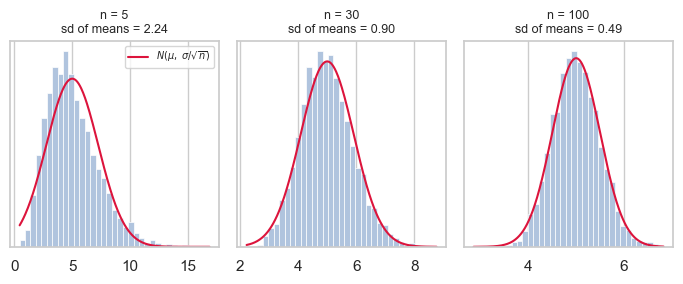

In [57]:
# (5) CLT SIMULATION: skewed exponential population, means of size n=5/30/100
rng = np.random.default_rng(7)
pop_mean, pop_sd = 5.0, 5.0          # Exp(lambda = 1/5): mean = sd = 5, heavily skewed

fig, axes = plt.subplots(1, 3, figsize=(7, 3))
for ax, n in zip(axes, (5, 30, 100)):
    samp_means = rng.exponential(scale=pop_mean, size=(4000, n)).mean(axis=1)
    ax.hist(samp_means, bins=35, density=True, color="lightsteelblue",
            edgecolor="white", linewidth=0.5)
    xs = np.linspace(samp_means.min(), samp_means.max(), 300)
    ax.plot(xs, st.norm.pdf(xs, pop_mean, pop_sd / np.sqrt(n)),
            color="crimson", lw=1.5, label=r"$N(\mu,\ \sigma/\sqrt{n})$")
    ax.set_title("n = %d\nsd of means = %.2f" % (n, samp_means.std(ddof=1)),
                 fontsize=9)
    ax.set_yticks([])
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()


In [58]:
# CLT honesty check: the distribution of MEANS is normal; the raw data is NOT
raw = rng.exponential(scale=pop_mean, size=4000)
print("raw exponential: skew = %.3f  (not normal!)" % st.skew(raw))
means100 = rng.exponential(scale=pop_mean, size=(4000, 100)).mean(axis=1)
print("means of n=100 : skew = %.3f  (near normal)" % st.skew(means100))
print("Shapiro on 1000 of those means: p = %.4f" % st.shapiro(means100[:1000]).pvalue)


raw exponential: skew = 2.021  (not normal!)
means of n=100 : skew = 0.222  (near normal)
Shapiro on 1000 of those means: p = 0.0001


### CLT — the three conditions
If $X_1,\dots,X_n$ are **i.i.d.** with mean $\mu$ and finite variance $\sigma^2$, then
$$\bar X_n \ \dot\sim\ N\!\left(\mu,\ \frac{\sigma^2}{n}\right)
\quad\text{and}\quad Z=\frac{\bar X-\mu}{\sigma/\sqrt n}\ \to\ N(0,1)$$
1. **Independent** observations (random sampling; no time-series dependence).
2. **Identically distributed** (same process drew every observation).
3. **Finite variance** and $n$ “large enough” — the classic rule of thumb is
   $n \gtrsim 30$; fewer is fine for symmetric populations, more is needed for
   heavy skew (try the histogram above with `n = 5`).

**What CLT does NOT say:** your data becomes normal — only the *sample means*
do. Raw exponential data stays skewed forever.

> **Gotcha:** the CLT is about $\bar X$, so the standard deviation of $\bar X$ is
> $\sigma/\sqrt n$ (**standard error**), *not* $\sigma$ (the population spread).
> Confusing SE with SD is the most common CI mistake.

**Section notes — normal + CLT:**

| Task | Code |
|---|---|
| percentile from z | `st.norm.cdf(z)` |
| z from percentile | `st.norm.ppf(p)` |
| non-standard normal | `st.norm(mu, sigma).cdf(x)` / `.ppf(p)` |
| 68-95-99.7 | empirical only for normal data |
| standard error | `sigma / np.sqrt(n)` (estimate: `s / np.sqrt(n)`) |
| CLT | distribution of $\bar X$, not of $X$ |

---
## 12. Estimation — confidence intervals & bootstrap

▶ Session 44 - Confidence Intervals: https://www.youtube.com/watch?v=X52HK2qkiIE

### Point vs interval estimate
- **Point estimate:** a single guess for the parameter — $\hat\mu = \bar x$.
  It is *never* exactly right and its variability is the **standard error**.
- **Interval estimate:** a range built to capture the parameter with stated
  confidence — the **confidence interval (CI)**.

| Known? | Interval | Formula |
|---|---|---|
| $\sigma$ known (or large n) | z-interval | $\bar x \pm z_{\alpha/2}\dfrac{\sigma}{\sqrt n}$ |
| $\sigma$ unknown, small n | t-interval | $\bar x \pm t_{\alpha/2,\,n-1}\dfrac{s}{\sqrt n}$ |

**Margin of error** $ME = z^*\cdot\dfrac{\sigma}{\sqrt n}$ (or $t^*\cdot s/\sqrt n$) —
the half-width. ME ∝ 1/√n (4× data → ½ error) and ∝ critical value (higher
confidence → wider interval).

In [59]:
rng = np.random.default_rng(2023)
heights = rng.normal(loc=167, scale=7.5, size=45)   # sample of heights (cm)
n, xbar, s = len(heights), heights.mean(), heights.std(ddof=1)
se = s / np.sqrt(n)
sigma_known = 7.5                                    # pretend sigma is known

# (a) z-interval with KNOWN sigma
ci_z = st.norm.interval(0.95, loc=xbar, scale=sigma_known / np.sqrt(n))
# (b) t-interval with UNKNOWN sigma (df = n - 1)
ci_t = st.t.interval(0.95, df=n - 1, loc=xbar, scale=se)

print("n = %d   x_bar = %.3f   s = %.3f   SE = %.4f" % (n, xbar, s, se))
print("95%% CI, z (sigma known): (%.3f, %.3f)  half-width %.3f"
      % (ci_z[0], ci_z[1], (ci_z[1] - ci_z[0]) / 2))
print("95%% CI, t (sigma unknown): (%.3f, %.3f)  half-width %.3f"
      % (ci_t[0], ci_t[1], (ci_t[1] - ci_t[0]) / 2))
print("t critical (df=44, .975) = %.4f  vs  z* = %.4f"
      % (st.t.ppf(0.975, n - 1), st.norm.ppf(0.975)))


n = 45   x_bar = 166.684   s = 7.410   SE = 1.1046
95% CI, z (sigma known): (164.493, 168.875)  half-width 2.191
95% CI, t (sigma unknown): (164.458, 168.910)  half-width 2.226
t critical (df=44, .975) = 2.0154  vs  z* = 1.9600


### How to interpret a 95% CI — and how NOT to
**Correct:** *“If we repeated this study many times and built a 95% interval
each time, 95% of those intervals would contain the true μ. For this particular
sample, the interval [164.5, 168.9] is one such interval.”*

**Wrong (interview killers):**
- ✗ “95% probability that μ lies in this interval” — a frequentist interval is
  fixed once computed; it either contains μ or it does not. (Bayesians may say
  this *with a prior* — frequentists may not.)
- ✗ “95% of the data lies in this interval” — that's a *tolerance/prediction*
  interval question, not a CI for the mean.
- ✗ “95% of the samples would fall here” — again a prediction interval.
- ✗ “the p-value would be < 0.05” — not equivalent (CIs and tests agree only
  for two-sided α = 0.05 with the same model).

In [60]:
# effect of n and of the confidence level on the margin of error
print("confidence level effect (SE fixed):")
for conf in (0.90, 0.95, 0.99):
    crit = st.norm.ppf((1 + conf) / 2)
    print("  %.0f%% CI -> z* = %.4f  half-width = %.3f"
          % (100 * conf, crit, crit * se))

print("\nn effect (95%% CI, sigma = 7.5 known):")
for m in (25, 100, 400, 1600, 10_000):
    me = st.norm.ppf(0.975) * sigma_known / np.sqrt(m)
    print("  n = %6d -> margin of error = %.3f cm" % (m, me))


confidence level effect (SE fixed):
  90% CI -> z* = 1.6449  half-width = 1.817
  95% CI -> z* = 1.9600  half-width = 2.165
  99% CI -> z* = 2.5758  half-width = 2.845

n effect (95%% CI, sigma = 7.5 known):
  n =     25 -> margin of error = 2.940 cm
  n =    100 -> margin of error = 1.470 cm
  n =    400 -> margin of error = 0.735 cm
  n =   1600 -> margin of error = 0.367 cm
  n =  10000 -> margin of error = 0.147 cm


In [61]:
# bootstrap CI — no distributional assumption at all
rng_boot = np.random.default_rng(0)
# resample n observations with replacement, B times (loop equivalent:
#   rng_boot.choice(heights, size=n, replace=True).mean()  for each b)
B = 5000
idx = rng_boot.integers(0, n, size=(B, n))           # default_rng resampling
boot_means = heights[idx].mean(axis=1)
boot_ci = np.percentile(boot_means, [2.5, 97.5])

print("bootstrap mean  = %.3f   (sample mean %.3f)" % (boot_means.mean(), xbar))
print("95%% bootstrap CI = (%.3f, %.3f)" % (boot_ci[0], boot_ci[1]))
print("95%% t CI         = (%.3f, %.3f)  <- close, both valid" % (ci_t[0], ci_t[1]))
print("bootstrap sd of means = %.4f   vs  s/sqrt(n) = %.4f"
      % (boot_means.std(ddof=1), se))


bootstrap mean  = 166.664   (sample mean 166.684)
95% bootstrap CI = (164.433, 168.808)
95% t CI         = (164.458, 168.910)  <- close, both valid
bootstrap sd of means = 1.1067   vs  s/sqrt(n) = 1.1046


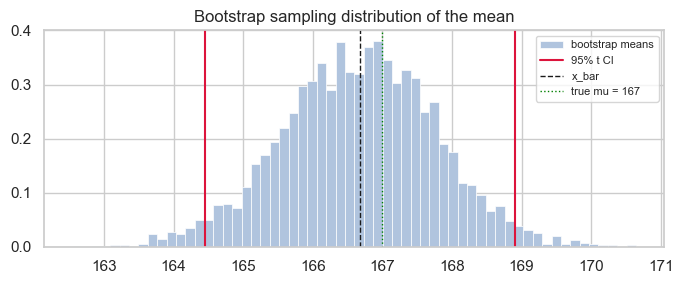

In [62]:
# visual: 95% CI and the sampling distribution of the mean
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(boot_means, bins=60, density=True, color="lightsteelblue",
        edgecolor="white", linewidth=0.5, label="bootstrap means")
ax.axvline(ci_t[0], color="crimson", lw=1.5, label="95% t CI")
ax.axvline(ci_t[1], color="crimson", lw=1.5)
ax.axvline(xbar, color="k", lw=1, ls="--", label="x_bar")
ax.axvline(167, color="green", lw=1, ls=":", label="true mu = 167")
ax.set_title("Bootstrap sampling distribution of the mean")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Section notes — estimation:**

| Piece | Code / formula |
|---|---|
| standard error | `s / np.sqrt(n)` |
| z-interval | `st.norm.interval(conf, loc=xbar, scale=sigma/sqrt(n))` |
| t-interval | `st.t.interval(conf, df=n-1, loc=xbar, scale=se)` |
| margin of error | `crit * se` — halves when n × 4 |
| bootstrap CI | resample with `default_rng`, take `np.percentile([2.5, 97.5])` |

> **TIP:** bootstrap CIs assume nothing about the shape of the data — perfect
> for skewed statistics (median, ratios, AUC) where a t-interval is not valid.

---
## 13. Hypothesis testing — the framework

▶ Session 45 - Hypothesis Testing Part 1: https://www.youtube.com/watch?v=S94mx6OL7kM

### The vocabulary
- **Null hypothesis $H_0$** — the boring “nothing changed” claim
  ($\mu = \mu_0$, no association, fair coin). You assume it true *to test it*.
- **Alternative $H_1$/$H_a$** — what you'd conclude if the data are unlikely
  under $H_0$. **Direction decides the tail:**
  - two-tailed: $H_1: \mu \ne \mu_0$ (default)
  - one-tailed: $H_1: \mu > \mu_0$ or $\mu < \mu_0$ (must be decided *before*
    seeing the data — never switch after)
- **Significance level $\alpha$** — the maximum false-alarm rate you tolerate.
  Convention: 0.05 (also 0.01, 0.10). It is a *decision threshold*, not a
  property of the data.
- **Test statistic** — how far the sample is from $H_0$ *in standard-error units*,
  e.g. $z = \dfrac{\bar x - \mu_0}{\sigma/\sqrt n}$ or $t = \dfrac{\bar x - \mu_0}{s/\sqrt n}$.
- **p-value** — *“the probability of obtaining data at least as contradictory
  to $H_0$ as what we observed, **assuming $H_0$ is true**.”*
- **Critical region** — values of the test statistic where $p < \alpha$
  (equivalently $|statistic| > z^*$).

In [63]:
# every hypothesis test is this five-line skeleton (z-test, sigma known)
mu0, sigma = 100.0, 15.0
rng = np.random.default_rng(6)
sample = rng.normal(loc=103, scale=15, size=60)

xbar, se = sample.mean(), sigma / np.sqrt(len(sample))
z = (xbar - mu0) / se
p_two, p_right = 2 * st.norm.sf(abs(z)), st.norm.sf(z)

print("x_bar = %.3f   SE = sigma/sqrt(n) = %.4f" % (xbar, se))
print("test statistic z = (x_bar - mu0)/SE = %.4f" % z)
print("p-value  two-tailed = %.4f   right-tailed = %.4f" % (p_two, p_right))
print("critical z* (alpha=0.05, two-tailed) = %.4f" % st.norm.ppf(0.975))
print("decision at alpha = 0.05 ->", "REJECT H0" if p_two < 0.05 else "FAIL TO REJECT H0")


x_bar = 104.952   SE = sigma/sqrt(n) = 1.9365
test statistic z = (x_bar - mu0)/SE = 2.5572
p-value  two-tailed = 0.0106   right-tailed = 0.0053
critical z* (alpha=0.05, two-tailed) = 1.9600
decision at alpha = 0.05 -> REJECT H0


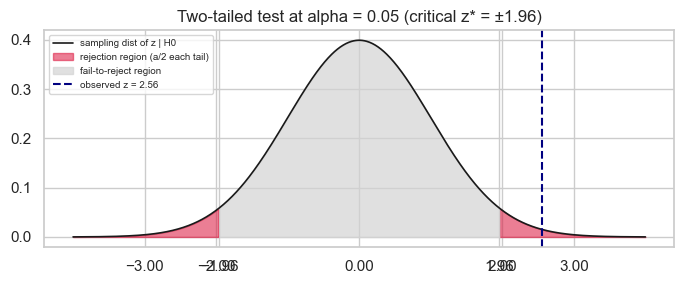

In [64]:
# the critical region, drawn
xs = np.linspace(-4, 4, 800)
crit = st.norm.ppf(0.975)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(xs, st.norm.pdf(xs), color="k", lw=1.2, label="sampling dist of z | H0")
ax.fill_between(xs, 0, st.norm.pdf(xs), where=(xs <= -crit),
                color="crimson", alpha=0.55, label="rejection region (a/2 each tail)")
ax.fill_between(xs, 0, st.norm.pdf(xs), where=(xs >= crit),
                color="crimson", alpha=0.55)
ax.fill_between(xs, 0, st.norm.pdf(xs), where=(np.abs(xs) <= crit),
                color="lightgray", alpha=0.7, label="fail-to-reject region")
ax.axvline(z, color="navy", lw=1.5, ls="--", label="observed z = %.2f" % z)
ax.set_xticks([-3, -2, -1.96, 0, 1.96, 2, 3])
ax.legend(fontsize=7, loc="upper left")
ax.set_title("Two-tailed test at alpha = 0.05 (critical z* = ±1.96)")
plt.tight_layout()
plt.show()


### The 7-step template (write this in the exam)
1. **State** $H_0$ and $H_1$ (with the correct tail).
2. **Choose** the test, based on data type, sample size, assumptions.
3. **Set** $\alpha$ (usually 0.05) before looking at results.
4. **Check** assumptions (normality, independence, equal variances).
5. **Compute** the test statistic and the p-value.
6. **Decide:** $p < \alpha$ → reject $H_0$; else fail to reject $H_0$.
7. **Interpret** in plain English *in context*, with effect size + CI — never
   just “p < 0.05”.

### Type I, Type II, and power

| | $H_0$ is TRUE | $H_0$ is FALSE |
|---|---|---|
| **reject $H_0$** | ✗ **Type I error** (false alarm), probability = $\alpha$ | ✓ correct (**power** = $1-\beta$) |
| **fail to reject** | ✓ correct (probability $1-\alpha$) | ✗ **Type II error** (miss), probability = $\beta$ |

- **Reduce $\alpha$** (e.g. 0.05 → 0.01): fewer false alarms, but *more* misses → power drops.
- **Increase $n$**: shrinks the standard error → power ↑ without raising $\alpha$ (the best fix).
- **Power** = P(reject $H_0$ | $H_0$ false) — depends on effect size, $\alpha$, $n$, variance.

In [65]:
# power intuition: same true effect, different n
def quick_power(n, true_delta, sigma=15.0, alpha=0.05):
    """Simulated power of a two-sided one-sample z-test."""
    rng = np.random.default_rng(99)
    draws = rng.normal(loc=mu0 + true_delta, scale=sigma, size=(4000, n))
    zvals = (draws.mean(axis=1) - mu0) / (sigma / np.sqrt(n))
    return np.mean(np.abs(zvals) > st.norm.ppf(1 - alpha / 2))

for n in (10, 30, 60, 120, 400):
    print("n = %4d  power = %.3f" % (n, quick_power(n, true_delta=3.0)))
print("(same effect of 3 units the whole time — only n changes)")


n =   10  power = 0.090
n =   30  power = 0.190
n =   60  power = 0.342
n =  120  power = 0.585
n =  400  power = 0.982
(same effect of 3 units the whole time — only n changes)


> **Gotcha — the p-value is NOT…**
> - …P($H_0$ is true | data) — that would be Bayesian (needs a prior).
> - …P(results are due to chance / a false positive rate).
> - …the probability the effect is real, nor the size of the effect.
> - …something you compare to $\alpha/2$, or report as “p = 0.000” —
>   write `p < 0.001` (p is never exactly 0).

**Small p means:** the data would be surprising *if* $H_0$ were true →
weakens $H_0$. It says nothing about *how big* or *important* the effect is —
with $n = 100\,000$, a 0.1% difference gets `p < 0.001`.

In [66]:
# **Section notes — hypothesis testing:**
#
# | Piece | Meaning |
# |---|---|
# | $H_0$ / $H_1$ | boring claim / what you want to show |
# | $\alpha$ | pre-set false-alarm budget (0.05) |
# | test statistic | distance from $H_0$ in SE units |
# | p-value | P(data this extreme \| $H_0$ true) |
# | decision | $p < \alpha$ → reject $H_0$ |
# | errors | $\alpha$ = Type I (false alarm), $\beta$ = Type II (miss) |
# | power | $1-\beta$ — fix low power by increasing $n$ |


---
## 14. z-test vs t-tests — one-sample, two-sample, paired

▶ Session 46 - Hypothesis Testing Part 2 | p-values | t-tests: https://www.youtube.com/watch?v=xHTMjxx14sU

| | z-test | t-test |
|---|---|---|
| σ | **known** (rare!) | **unknown**, estimated by $s$ |
| reference dist | $N(0,1)$ | $t_{n-1}$ (heavier tails) |
| sample size | any with known σ; large n makes $t \approx z$ | small n is exactly when t is needed |
| scipy | no `ttest`-style function — use `st.norm.sf/cdf` | `st.ttest_1samp/ind/rel` |

**Assumptions every t-test needs:** (1) observations independent,
(2) approximately normal within each group (or $n \gtrsim 30$ by CLT),
(3) **equal variances** only for the *Student* two-sample variant —
use **Welch** (`equal_var=False`) when in doubt (it is the safe default;
Welch's correction adjusts the degrees of freedom).

In [67]:
rng = np.random.default_rng(12)
control = rng.normal(52, 8, 35)
treated = rng.normal(60, 9, 38)

# --- (1) one-sample t-test: is this group's mean different from 50? ---
one = st.ttest_1samp(control, popmean=50)
print("one-sample  : t = %+.3f  p = %.4f  df = %d" % (one.statistic, one.pvalue, one.df))

# --- (2) two-sample independent: Student vs Welch ---
student = st.ttest_ind(control, treated)                      # equal_var=True (default)
welch = st.ttest_ind(control, treated, equal_var=False)       # Welch (preferred)
print("Student t   : t = %+.3f  p = %.4f  df = %.1f"
      % (student.statistic, student.pvalue, student.df))
print("Welch       : t = %+.3f  p = %.4f  df = %.1f"
      % (welch.statistic, welch.pvalue, welch.df))
print("difference in means = %.3f" % (treated.mean() - control.mean()))

# --- (3) paired t-test: same subjects before/after ---
before = rng.normal(70, 6, 25)
after = before + rng.normal(4, 5, 25)          # paired: after built from before
paired = st.ttest_rel(before, after)
diff = after - before
print("paired      : t = %+.3f  p = %.4f  df = %d   (mean diff %+.2f)"
      % (paired.statistic, paired.pvalue, paired.df, diff.mean()))
print("a paired test on UNEQUAL n would fail:", end=" ")
try:
    st.ttest_rel(before, after[:10])
except ValueError as e:
    print("ValueError:", str(e)[:60], "...")


one-sample  : t = +1.383  p = 0.1756  df = 34
Student t   : t = -4.942  p = 0.0000  df = 71.0
Welch       : t = -4.981  p = 0.0000  df = 70.2
difference in means = 9.336
paired      : t = -4.171  p = 0.0003  df = 24   (mean diff +4.02)
a paired test on UNEQUAL n would fail: ValueError: unequal length arrays ...


### Checking the assumptions
- **Normality** — Shapiro-Wilk `st.shapiro(x)` (per group, or on residuals;
  valid up to n = 5000). $p > 0.05$ → no evidence against normality
  (with tiny n it has no power; with huge n it rejects harmless deviations —
  also eyeball a Q-Q plot / histogram).
- **Equal variance** — Levene `st.levene(a, b)` (more robust than Bartlett).
  $p < 0.05$ → use Welch, not Student.

In [68]:
resid = np.concatenate([control - control.mean(), treated - treated.mean()])
sw = st.shapiro(resid)
lv = st.levene(control, treated)
print("Shapiro on residuals : W = %.4f  p = %.4f  -> %s"
      % (sw.statistic, sw.pvalue, "looks normal" if sw.pvalue > 0.05 else "non-normal"))
print("Levene equal variance: W = %.3f  p = %.4f  -> %s"
      % (lv.statistic, lv.pvalue, "equal var OK" if lv.pvalue > 0.05 else "use Welch"))
# too much power at large n:
big = st.shapiro(rng.normal(0, 1, 4000))
print("n = 4000 perfect normal data -> Shapiro p = %.2e (over-sensitive!)" % big.pvalue)


Shapiro on residuals : W = 0.9895  p = 0.8082  -> looks normal
Levene equal variance: W = 0.800  p = 0.3742  -> equal var OK
n = 4000 perfect normal data -> Shapiro p = 5.50e-01 (over-sensitive!)


### Effect size — Cohen's $d$
$$d = \frac{\bar x_1 - \bar x_2}{s_{\text{pooled}}},\qquad
s_{\text{pooled}} = \sqrt{\frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2}}$$
Rule of thumb: **0.2 small · 0.5 medium · 0.8 large**. A tiny p-value with
$d = 0.05$ is a trivial effect the study was simply big enough to detect.

In [69]:
def cohens_d(a, b):
    n1, n2 = len(a), len(b)
    s_pool = np.sqrt(((n1 - 1) * a.std(ddof=1) ** 2 + (n2 - 1) * b.std(ddof=1) ** 2)
                     / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / s_pool, s_pool

d, s_pool = cohens_d(control, treated)
print("pooled sd = %.3f   Cohen's d = %+.3f  -> %s"
      % (s_pool, d,
         "large" if abs(d) >= 0.8 else "medium" if abs(d) >= 0.5 else "small"))


pooled sd = 8.063   Cohen's d = -1.158  -> large


### `scipy.stats.mannwhitneyu(x, y)` — non-parametric alternative
**What it does:** compares *ranks* instead of means — no normality assumption.
**Use when:** ordinal data, heavy skew/outliers, tiny n, or Shapiro fails.
**Hypothesis:** about distributions (P(X > Y) = 0.5), not strictly about means —
if the shapes differ, it is not “a test of medians”.
**Parameters:** `alternative` — `'two-sided'` (default) / `'less'` / `'greater'`.

In [70]:
u_stat, u_p = st.mannwhitneyu(control, treated, alternative="two-sided")
print("Mann-Whitney U = %.1f  p = %.4f" % (u_stat, u_p))
print("Welch t-test   p = %.4f  (same conclusion here)" % welch.pvalue)
# skewed data where the mean misleads:
skewed = np.concatenate([rng.normal(60, 8, 30), [130.0, 140.0]])
print("Shapiro on skewed data: p = %.4f -> prefer Mann-Whitney"
      % st.shapiro(skewed).pvalue)


Mann-Whitney U = 281.0  p = 0.0000
Welch t-test   p = 0.0000  (same conclusion here)
Shapiro on skewed data: p = 0.0000 -> prefer Mann-Whitney


**Section notes — t-tests:**

| Question | Test | scipy |
|---|---|---|
| mean vs known value | one-sample t | `st.ttest_1samp(x, mu0)` |
| two independent means | Student / Welch t | `st.ttest_ind(a, b, equal_var=False)` |
| two paired means | paired t | `st.ttest_rel(a, b)` |
| 2 groups, non-normal | Mann-Whitney U | `st.mannwhitneyu(a, b)` |
| normality check | Shapiro-Wilk | `st.shapiro(x)` |
| equal-variance check | Levene | `st.levene(a, b)` |
| effect size | Cohen's d | manual (above) |

---
## 15. Chi-square tests — goodness of fit & independence

▶ Session on Chi Square Tests: https://www.youtube.com/watch?v=_8DTqznosvY

### Test 1 — Goodness of fit: observed vs a claimed distribution
$$\chi^2 = \sum_{i=1}^{k} \frac{(O_i - E_i)^2}{E_i}$$
- $O_i$ observed counts, $E_i = n \cdot p_i$ expected counts.
- **df = k − 1 − m**, where $m$ = number of parameters *estimated from the data*
  (e.g. fitting a mean before binning → subtract 1 more).
- **Expected-count rule (Cochran):** no $E_i < 1$ and **no more than 20% of
  $E_i < 5$** — otherwise merge categories or collect more data.
- `scipy.stats.chisquare(observed, f_exp=expected)` (1-D counts).
  For a 2-D table use `chi2_contingency` (test of independence, next).

In [71]:
# is this die fair? 600 rolls
observed = np.array([92, 108, 100, 95, 105, 100])
expected = np.full(6, observed.sum() / 6)          # n * 1/6 each
chi2_gof, p_gof = st.chisquare(observed, f_exp=expected)

print("observed :", observed)
print("expected : %.1f each" % expected[0])
print("chi2 = %.3f   df = k - 1 - m = 6 - 1 - 0 = 5   p = %.4f" % (chi2_gof, p_gof))
print("min expected = %.1f  (all >= 5 -> rule satisfied)" % expected.min())
print("decision: ", "REJECT (die is unfair)" if p_gof < 0.05 else "fail to reject (die looks fair)")


observed : [ 92 108 100  95 105 100]
expected : 100.0 each
chi2 = 1.780   df = k - 1 - m = 6 - 1 - 0 = 5   p = 0.8787
min expected = 100.0  (all >= 5 -> rule satisfied)
decision:  fail to reject (die looks fair)


In [72]:
# with m = 1 estimated parameter, df drops: uniform is no longer the right model
# e.g. testing a normal model whose mean/sd came from the SAME data
rng = np.random.default_rng(3)
sample_cont = rng.normal(50, 10, 1000)
edges = np.linspace(20, 80, 7)
counts, _ = np.histogram(sample_cont, bins=edges)
fitted = st.norm(sample_cont.mean(), sample_cont.std(ddof=1))   # mean & sd FROM this data
probs = np.diff(fitted.cdf(edges))                              # model-implied bin probs
exp_cnt = probs * counts.sum()
exp_cnt *= counts.sum() / exp_cnt.sum()            # renormalise (bins don't cover (-inf, inf))
chi2_c, p_c = st.chisquare(counts, f_exp=exp_cnt)
k, m = len(counts), 2                               # mean & sd estimated from data
print("bins: k = %d, estimated params: m = %d -> df should be %d" % (k, m, k - 1 - m))
print("chi2 = %.3f, scipy assumes df = k-1 = %d -> p = %.4f"
      % (chi2_c, k - 1, p_c))
print("correct df = %d -> p = %.4f  (more honest, smaller df)"
      % (k - 1 - m, st.chi2.sf(chi2_c, k - 1 - m)))


bins: k = 6, estimated params: m = 2 -> df should be 3
chi2 = 1.705, scipy assumes df = k-1 = 5 -> p = 0.8882
correct df = 3 -> p = 0.6358  (more honest, smaller df)


### Test 2 — Independence: is one categorical variable related to another?
$$\chi^2 = \sum \frac{(O - E)^2}{E},\qquad
E_{ij} = \frac{(\text{row}_i\ \text{total})(\text{col}_j\ \text{total})}{n},
\qquad df = (r-1)(c-1)$$
`scipy.stats.chi2_contingency(table)` returns `(chi2, p, dof, expected)`.
> **Gotcha:** for a **2×2 table SciPy applies Yates' continuity correction by
> default** — pass `correction=False` to get the uncorrected Pearson χ².

**Cramér's V** (effect size for categorical association, 0–1):
$V = \sqrt{\dfrac{\chi^2}{n \cdot \min(r-1,\, c-1)}}$ — 0.1 small, 0.3 medium, 0.5 large.

In [73]:
# does physical activity level relate to disease severity?  (550 patients)
table = np.array([[150,  70,  30],      # sedentary:  no / mild / severe
                  [210,  85,  55]])     # active:     no / mild / severe
chi2_i, p_i, dof_i, exp_i = st.chi2_contingency(table)

print("row totals:", table.sum(axis=1), " col totals:", table.sum(axis=0), " N =", table.sum())
print("\nexpected counts:\n", np.round(exp_i, 2))
print("\nchi2 = %.3f   df = (r-1)(c-1) = %d   p = %.4f" % (chi2_i, dof_i, p_i))
print("cells with E < 5: %d of %d (rule: <= 20%%)" % ((exp_i < 5).sum(), exp_i.size))
v = np.sqrt(chi2_i / (table.sum() * min(table.shape[0] - 1, table.shape[1] - 1)))
print("Cramer's V = %.3f  -> weak association" % v)
print("decision: ", "REJECT independence" if p_i < 0.05 else "fail to reject: independent")


row totals: [250 350]  col totals: [360 155  85]  N = 600

expected counts:
 [[150.    64.58  35.42]
 [210.    90.42  49.58]]

chi2 = 2.199   df = (r-1)(c-1) = 2   p = 0.3330
cells with E < 5: 0 of 6 (rule: <= 20%)
Cramer's V = 0.061  -> weak association
decision:  fail to reject: independent


In [74]:
# default Yates correction visible on a 2x2 table
t22 = np.array([[30, 10], [20, 25]])
print("chi2_contingency (default, Yates):", np.round(st.chi2_contingency(t22)[:3], 4))
print("chi2_contingency (correction=False):",
      np.round(st.chi2_contingency(t22, correction=False)[:3], 4))


chi2_contingency (default, Yates): [6.9499 0.0084 1.    ]
chi2_contingency (correction=False): [8.1627e+00 4.3000e-03 1.0000e+00]


**Section notes — chi-square:**

| Test | scipy | df | Table check |
|---|---|---|---|
| goodness of fit | `st.chisquare(o, f_exp=e)` | $k-1-m$ | expected ≥ 5 (≤20% below 5) |
| independence | `st.chi2_contingency(t)` | $(r-1)(c-1)$ | expected ≥ 5 |
| effect size | Cramér's V | — | $\sqrt{\chi^2/(n\cdot\min(r-1,c-1))}$ |

> **Gotcha:** χ² tests work on **counts**, not percentages or means — and they
> are always **right-tailed** (`st.chi2.sf(chi2, df)` is the p-value).

---
## 16. ANOVA — comparing 3+ means

▶ Session on ANOVA: https://www.youtube.com/watch?v=G9ppvMWyd54

### One-way ANOVA
- $H_0$: $\mu_1 = \mu_2 = \dots = \mu_k$ (all group means equal)
- $H_1$: at least one mean differs (only this — ANOVA does **not** say which)
- **F statistic:** $F = \dfrac{\text{MSB}}{\text{MSW}}$ with
  $dfn = k-1$, $dfd = n-k$, where
  $SSB = \sum n_i(\bar x_i - \bar x)^2$ (between) and
  $SSW = \sum \sum (x_{ij} - \bar x_i)^2$ (within).
- Large $F$ ⇒ group differences dominate the noise ⇒ small p (`st.f.sf(F, dfn, dfd)`).

**Why not just run $\binom{k}{2}$ t-tests?** Each test burns $\alpha$, so with 3
groups you get $1-(1-\alpha)^3 = 14.3\%$ false-positive rate at $\alpha=0.05$.
**Bonferroni fix:** test each pair at $\alpha/m$ ($m$ = number of comparisons).

In [75]:
rng = np.random.default_rng(11)
a = rng.normal(4.5, 1.2, 30)     # three teaching methods, exam scores
b = rng.normal(6.0, 1.2, 30)
c = rng.normal(5.2, 1.2, 30)

F, p = st.f_oneway(a, b, c)
print("scipy F = %.4f   p = %.5f" % (F, p))

# hand-computed ANOVA table (proves what scipy did)
groups = [a, b, c]
grand = np.concatenate(groups).mean()
ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ssw = sum(((g - g.mean()) ** 2).sum() for g in groups)
dfb, dfw = len(groups) - 1, sum(len(g) for g in groups) - len(groups)
msb, msw = ssb / dfb, ssw / dfw
print("SSB = %.3f (df %d)   SSW = %.3f (df %d)" % (ssb, dfb, ssw, dfw))
print("F = MSB/MSW = %.3f/%.3f = %.4f   p = %.5f"
      % (msb, msw, msb / msw, st.f.sf(msb / msw, dfb, dfw)))
print("eta-squared = SSB/(SSB+SSW) = %.3f  (variance explained by method)" % (ssb / (ssb + ssw)))


scipy F = 19.2159   p = 0.00000
SSB = 45.319 (df 2)   SSW = 102.590 (df 87)
F = MSB/MSW = 22.659/1.179 = 19.2159   p = 0.00000
eta-squared = SSB/(SSB+SSW) = 0.306  (variance explained by method)


In [76]:
# why multiple t-tests inflate errors: Bonferroni correction
from itertools import combinations
names, groups_d = ["A", "B", "C"], {"A": a, "B": b, "C": c}
alpha, m = 0.05, math.comb(3, 2)
print("comparisons m = C(3,2) = %d   Bonferroni alpha = %.4f" % (m, alpha / m))
for g1, g2 in combinations(names, 2):
    t, pv = st.ttest_ind(groups_d[g1], groups_d[g2])
    print("  %s vs %s: p = %.4f | raw %.05f: %-5s | Bonferroni: %s"
          % (g1, g2, pv, pv, pv < alpha, "sig" if pv < alpha / m else "not sig"))


comparisons m = C(3,2) = 3   Bonferroni alpha = 0.0167
  A vs B: p = 0.0000 | raw 0.00000: True  | Bonferroni: sig
  A vs C: p = 0.0005 | raw 0.00049: True  | Bonferroni: sig
  B vs C: p = 0.0198 | raw 0.01984: True  | Bonferroni: not sig


In [77]:
# post-hoc after a significant ANOVA: Tukey HSD (all pairwise, family-wise 5%)
values = np.concatenate(groups)
labels = np.repeat(["A", "B", "C"], 30)
tukey = mc.pairwise_tukeyhsd(values, labels, alpha=0.05)
print(tukey)


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B    1.724    0.0  1.0554  2.3925   True
     A      C   1.0539 0.0009  0.3854  1.7225   True
     B      C    -0.67 0.0494 -1.3386 -0.0015   True
----------------------------------------------------

normality per group (Shapiro p): [np.float64(0.782), np.float64(0.059), np.float64(0.48)]
equal variances (Levene p)     : 0.888
Kruskal-Wallis H = 26.653  p = 0.00000  (non-parametric alternative)


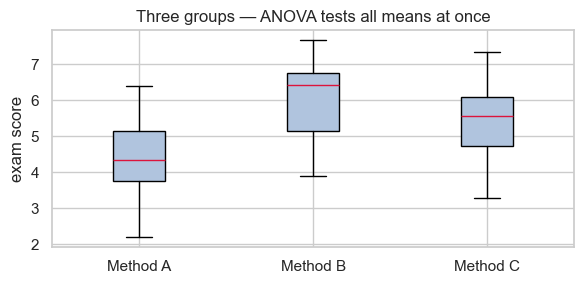

In [78]:
# assumptions + the non-parametric fallback
print("normality per group (Shapiro p):",
      [round(st.shapiro(g).pvalue, 3) for g in groups])
print("equal variances (Levene p)     : %.3f" % st.levene(a, b, c).pvalue)
h, p_kw = st.kruskal(a, b, c)
print("Kruskal-Wallis H = %.3f  p = %.5f  (non-parametric alternative)" % (h, p_kw))

fig, ax = plt.subplots(figsize=(6, 3))
ax.boxplot(groups, tick_labels=["Method A", "Method B", "Method C"],
           patch_artist=True,
           boxprops=dict(facecolor="lightsteelblue"),
           medianprops=dict(color="crimson"))
ax.set_ylabel("exam score")
ax.set_title("Three groups — ANOVA tests all means at once")
plt.tight_layout()
plt.show()


### ANOVA assumptions & alternatives

| Assumption | Check / fix |
|---|---|
| independence | study design (random assignment) |
| normality within groups | Shapiro on residuals / Q-Q; CLT rescues n ≥ 30 |
| homogeneity of variances | Levene → if violated use **Welch's ANOVA** (`pingouin`/`statsmodels`) |
| balanced-ish design | unbalanced is fine for one-way ANOVA |

**Non-parametric:** **Kruskal-Wallis** (`st.kruskal`) — ranks, no normality
assumption; test of stochastic dominance (medians if shapes match).
**Two-factor ANOVA:** `statsmodels.formula.api.ols('y ~ C(a) + C(b)').fit()`
then `statsmodels.stats.anova.anova_lm(...)` (in the ML notebook).

> **Gotcha:** a **significant ANOVA only says “somewhere there's a difference.”**
> Follow with a post-hoc (Tukey HSD) to find *which* pairs differ; a
> **non-significant ANOVA** does not license peeking at pairwise t-tests.

In [79]:
# **Section notes — ANOVA:**
#
# | Test | scipy | Hypothesis |
# |---|---|---|
# | one-way ANOVA | `st.f_oneway(a, b, c)` | all $\mu_i$ equal? |
# | post-hoc | `mc.pairwise_tukeyhsd(values, labels)` | which pairs differ |
# | non-parametric | `st.kruskal(a, b, c)` | distributions equal (rank-based) |
# | effect size | $\eta^2 = SSB/(SSB+SSW)$ | variance explained |


---
## 17. Test-selection cheat sheet, p-value wording & interview Q&A

▶ Session 45 - Hypothesis Testing Part 1: https://www.youtube.com/watch?v=S94mx6OL7kM
▶ Session 46 - Hypothesis Testing Part 2 | p-values | t-tests: https://www.youtube.com/watch?v=xHTMjxx14sU

### Goal → test → scipy function → assumptions

| Goal | Test | scipy function | Assumptions |
|---|---|---|---|
| 1 mean vs known value, σ known | z-test | `st.norm.sf/cdf` | normal / large n |
| 1 mean vs known value, σ unknown | one-sample t | `st.ttest_1samp(x, mu0)` | independence, ≈ normal |
| 2 independent means | independent t / Welch | `st.ttest_ind(a, b, equal_var=False)` | ≈ normal, independent |
| 2 paired means (before/after) | paired t | `st.ttest_rel(a, b)` | differences ≈ normal |
| 2 groups, non-normal / ordinal | Mann-Whitney U | `st.mannwhitneyu(a, b)` | independent samples |
| 3+ means | one-way ANOVA | `st.f_oneway(a, b, c)` | normal, equal var, independent |
| 3+ groups, non-normal | Kruskal-Wallis | `st.kruskal(a, b, c)` | independent, ordinal/continuous |
| counts vs theoretical distribution | χ² goodness of fit | `st.chisquare(o, f_exp=e)` | expected ≥ 5 |
| two categorical variables | χ² independence | `st.chi2_contingency(t)` | expected ≥ 5 |
| 1 mean vs hypothesised proportion | 1-prop z-test | `st.norm.sf(...)` | np ≥ 5, n(1−p) ≥ 5 |
| linear association, 2 continuous | Pearson / Spearman | `st.pearsonr` / `st.spearmanr` | linearity / monotonic |
| spread of 2 variances | F-test of variances | `st.f.cdf(...)` | both normal |
| correlation ≠ 0 | t-test on r | `pearsonr` p-value | bivariate normal |

### p-value → plain English (what you may write)

| p-value | Wording |
|---|---|
| p < 0.001 | very strong evidence against H₀ |
| 0.001 – 0.01 | strong evidence against H₀ |
| 0.01 – 0.05 | moderate evidence against H₀ |
| 0.05 – 0.10 | weak / inconclusive evidence |
| p > 0.10 | data are not unusual under H₀ — **not** proof that H₀ is true |

Always pair the decision with **effect size + CI**:
*“t(43) = 2.1, p = .04, d = 0.42, 95% CI [0.1, 8.6] — a moderate increase.”*

- ✗ “accept H₀” / “prove H₀” → ✓ “fail to reject H₀”
- ✗ “p = 0.000” → ✓ “p < 0.001”
- ✗ “significant, therefore important” → check **d** and the CI

### 10 rapid-fire interview questions

1. **Parameter vs statistic?** — $\mu,\sigma,p$ belong to the population;
   $\bar x, s, \hat p$ to the sample (they have sampling distributions).
2. **Why n−1 for variance?** — Bessel's correction: deviations around $\bar x$
   use up one degree of freedom; dividing by n underestimates $\sigma^2$.
3. **Correct p-value interpretation?** — P(data at least this extreme | $H_0$
   true). It is **not** P($H_0$ | data) and not the chance the result is luck.
4. **p = 0.03, α = 0.05 — conclusion?** — reject $H_0$; there is moderate
   evidence for $H_1$ *at this α* (α was chosen in advance).
5. **Type I vs Type II — how to reduce each?** — I (false alarm) ↓ by lowering
   α; II (miss) ↓ by raising α or, better, increasing **n** / effect size.
6. **z-test or t-test?** — known σ → z; unknown σ → t. As df → ∞, t → z.
7. **What does the CLT actually say?** — the *sampling distribution of x̄* is
   approximately $N(\mu, \sigma/\sqrt n)$ for large n (i.i.d., finite variance) —
   it says nothing about the raw data becoming normal.
8. **ANOVA vs several t-tests?** — k−1…$\binom{k}{2}$ tests inflate family-wise
   error to $1-(1-\alpha)^m$; ANOVA controls it at α, then Tukey/Bonferroni
   localise the difference.
9. **When is a mean a bad summary?** — skewed data (income), outliers, ordinal
   scales → use median/IQR or mode; report both when unsure.
10. **95% CI — the right sentence?** — “the procedure covers the true μ in 95%
    of repeated samples” (frequentist) — not “95% chance μ is in this interval”.

---
## Quick revision sheet

| Topic | Formula / function |
|---|---|
| mean / median / mode | `np.mean` · `np.median` · `pd.Series.mode()` |
| trimmed / geo / harmonic | `st.trim_mean(a, p)` · `st.gmean` · `st.hmean` |
| variance (sample) | `np.var(x, ddof=1)` · `pd.Series.var()` (ddof=1 default) |
| IQR / fences | `Q3-Q1` · `[Q1-1.5·IQR, Q3+1.5·IQR]` |
| z-score | $(x-\bar x)/s$ · percentile via `st.norm.cdf(z)` |
| covariance / correlation | `np.cov(x, y)` · `st.pearsonr` · `st.spearmanr` |
| Bayes | $P(A\|B)=P(B\|A)P(A)/P(B)$ · denominator = law of total prob. |
| E[X], Var(X) | $\sum x\,p(x)$, $E[X^2]-\mu^2$ · `dist.mean()`, `dist.var()` |
| binomial / Poisson | `st.binom(n, p)` ($np$, $np(1-p)$) · `st.poisson(mu)` (λ, λ) |
| standard error | $\sigma/\sqrt n$ → estimate $s/\sqrt n$ |
| 68-95-99.7 / Chebyshev | normal only / any dist: $P(\|X-\mu\|\ge k\sigma)\le 1/k^2$ |
| CI (σ known / unknown) | `norm.interval` · `st.t.interval(conf, df=n-1, loc, scale)` |
| bootstrap CI | resample w/ `default_rng` → `np.percentile([2.5, 97.5])` |
| p-value | P(data this extreme \| $H_0$) — decide with $p < \alpha$ |
| one/two-sample/paired t | `ttest_1samp` · `ttest_ind(equal_var=False)` · `ttest_rel` |
| assumptions | `st.shapiro` (normality), `st.levene` (equal var) |
| χ² GOF / independence | `st.chisquare` · `st.chi2_contingency` (df = k−1−m / (r−1)(c−1)) |
| ANOVA / non-parametric | `st.f_oneway` · `st.kruskal` · Tukey via statsmodels |

> **Interview short-list:** ddof 0 vs 1 · mean vs median on skewed data ·
> p ≠ P(H₀) · α vs β vs power · CLT conditions · why Welch by default ·
> χ² expected-count rule · ANOVA's F = MSB/MSW · CI correct wording ·
> Pearson vs Spearman · Bayesian vs frequentist one-liner.

---
**Next notebook:** `09_linear_algebra.ipynb` — vectors, matrices, eigenvalues,
SVD: the machinery that makes every model above computable.

**Playlist:** https://www.youtube.com/playlist?list=PLKnIA16_RmvbAlyx4_rdtR66B7EHX5k3z